# Computational Linear Algebra: SVD Homework

**Academic Year:** 2025/2026

### Team Members (Alphabetical Order):
1. Provenzano, Davide (S360754);
2. Solimando, Vincenzo (S349147).

Now, fill the python list below with the Student IDs of the team

In [1]:
StudentIDs = [360754,349147] 

## Starting Code-Cell 

In [2]:
import numpy as np
import pandas as pd
from IPython.display import display

var_entertainment_feat_types = ['Interests', 'Movies', 'Music']
var_personal_feat_types = ['Finance', 'Phobias']
fixed_feat_types = ['Personality', 'Health']

label_types = ['Demographic']

variables_by_type = {
    'Demographics': ['Age', 'Height', 'Weight', 'Number of siblings', 
                     'Gender', 'Hand', 'Education', 'Only child', 'Home Town Type',
                     'Home Type'],
    'Finance': ['Finances', 'Shopping centres', 'Branded clothing', 
                'Entertainment spending', 'Spending on looks', 
                'Spending on gadgets', 'Spending on healthy eating'],
    'Health': ['Smoking', 'Alcohol', 'Healthy eating'],
    'Interests': ['History', 'Psychology', 'Politics', 'Mathematics', 
                  'Physics', 'Internet', 'PC', 'Economy Management', 
                  'Biology', 'Chemistry', 'Reading', 'Geography', 
                  'Foreign languages', 'Medicine', 'Law', 'Cars', 
                  'Art exhibitions', 'Religion', 'Countryside, outdoors', 
                  'Dancing', 'Musical instruments', 'Writing', 'Passive sport', 
                  'Active sport', 'Gardening', 'Celebrities', 'Shopping', 
                  'Science and technology', 'Theatre', 'Fun with friends', 
                  'Adrenaline sports', 'Pets'],
    'Movies': ['Movies', 'Horror', 'Thriller', 'Comedy', 'Romantic', 
               'Sci-fi', 'War', 'Fantasy/Fairy tales', 'Animated', 
               'Documentary', 'Western', 'Action'],
    'Music': ['Music', 'Slow songs or fast songs', 'Dance', 'Folk', 
              'Country', 'Classical music', 'Musical', 'Pop', 'Rock', 
              'Metal or Hardrock', 'Punk', 'Hiphop, Rap', 'Reggae, Ska', 
              'Swing, Jazz', 'Rock n roll', 'Alternative', 'Latino', 
              'Techno, Trance', 'Opera'],
    'Personality': ['Daily events', 'Prioritising workload', 
                    'Writing notes', 'Workaholism', 'Thinking ahead', 
                    'Final judgement', 'Reliability', 'Keeping promises', 
                    'Loss of interest', 'Friends versus money', 'Funniness', 
                    'Fake', 'Criminal damage', 'Decision making', 'Elections', 
                    'Self-criticism', 'Judgment calls', 'Hypochondria', 
                    'Empathy', 'Eating to survive', 'Giving', 
                    'Compassion to animals', 'Borrowed stuff', 
                    'Loneliness', 'Cheating in school', 'Health', 
                    'Changing the past', 'God', 'Dreams', 'Charity', 
                    'Number of friends', 'Punctuality', 'Lying', 'Waiting', 
                    'New environment', 'Mood swings', 'Appearence and gestures', 
                    'Socializing', 'Achievements', 'Responding to a serious letter', 
                    'Children', 'Assertiveness', 'Getting angry', 
                    'Knowing the right people', 'Public speaking', 
                    'Unpopularity', 'Life struggles', 'Happiness in life', 
                    'Energy levels', 'Small - big dogs', 'Personality', 
                    'Finding lost valuables', 'Getting up', 'Interests or hobbies', 
                    "Parents' advice", 'Questionnaires or polls', 'Internet usage'],
    'Phobias': ['Flying', 'Storm', 'Darkness', 'Heights', 'Spiders', 'Snakes', 
                'Rats', 'Ageing', 'Dangerous dogs', 'Fear of public speaking']
}

labels = variables_by_type['Demographics']
features_all = []
for tt in variables_by_type.keys():
    if tt != 'Demographics':
        features_all += variables_by_type[tt]

def which_features(*StudentIDs):
    random_seed = min(StudentIDs)
    np.random.seed(random_seed)
    features_ = np.random.choice(features_all, int((2 * len(features_all)) / 3), replace=False).tolist()
    features = []
    features_by_type = {tt: [] for tt in variables_by_type.keys() if tt != 'Demographics'}
    for tt in variables_by_type.keys():
        ft_list = variables_by_type[tt]
        for ii in range(len(ft_list)):
            if ft_list[ii] in features_:
                features.append(ft_list[ii])
                features_by_type[tt].append(ft_list[ii])

    return features, features_by_type

features, features_by_type = which_features(*StudentIDs)

print(f'*** THESE ARE THE {len(features)} SELECTED FEATURES (SEE VARIABLE features):')
for ff in features:
    print(f'{ff}')
print('*************************************')
print('')
print('*** SELECTED FEATURES BY TYPES (SEE VARIABLE features_by_type):')
for tt in features_by_type.keys():
    print(f'{tt}: {features_by_type[tt]}')
    print('')
print('*************************************')
print('')
print('*** THESE ARE THE LABELS (SEE VARIABLE labels):')
for ll in labels:
    print(f'{ll}')
print('*************************************')

def which_rows(df, frac, *StudentIDs):
    random_seed = min(StudentIDs)
    df_ = df.sample(frac=frac, random_state=random_seed)
    return df_

responses_hw = pd.read_csv('responses_hw.csv', index_col=0)
responses = which_rows(responses_hw, 0.75, *StudentIDs)
responses = responses.loc[:, features + labels]

responses_ft = responses.loc[:, features]
responses_lb = responses.loc[:, labels]

print('')
print('*** THIS IS YOUR PERSONAL DATASET (features AND labels TOGETHER, SEE VARIABLE responses)')
display(responses)
print('')
print('*** THIS IS YOUR PERSONAL DATASET (features, SEE VARIABLE responses_ft)')
display(responses_ft)
print('')
print('*** THIS IS YOUR PERSONAL DATASET (labels, SEE VARIABLE responses_lb)')
display(responses_lb)

random_seed = min(StudentIDs)
np.random.seed(random_seed)

your_scaler = np.random.choice(['StandardScaler', 'MinMaxScaler'])


*** THESE ARE THE 93 SELECTED FEATURES (SEE VARIABLE features):
Finances
Entertainment spending
Spending on looks
Healthy eating
History
Psychology
Politics
Mathematics
Physics
Internet
PC
Economy Management
Biology
Reading
Medicine
Religion
Countryside, outdoors
Dancing
Musical instruments
Writing
Passive sport
Active sport
Gardening
Science and technology
Fun with friends
Movies
Horror
Thriller
Romantic
Sci-fi
War
Fantasy/Fairy tales
Animated
Western
Slow songs or fast songs
Folk
Country
Classical music
Reggae, Ska
Swing, Jazz
Rock n roll
Alternative
Latino
Techno, Trance
Opera
Prioritising workload
Writing notes
Thinking ahead
Final judgement
Reliability
Loss of interest
Funniness
Fake
Criminal damage
Decision making
Elections
Self-criticism
Hypochondria
Empathy
Compassion to animals
Cheating in school
Health
Changing the past
God
Dreams
Number of friends
Punctuality
Lying
Waiting
Mood swings
Socializing
Achievements
Responding to a serious letter
Children
Assertiveness
Getting angr

,Finances,Entertainment spending,Spending on looks,Healthy eating,History,Psychology,Politics,Mathematics,Physics,Internet,...,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
109,4,3,3,3,3,4,3,4,4,5,...,20,165,55,3,male,right,secondary school,no,village,house/bungalow
552,1,5,5,4,5,1,1,1,1,5,...,17,175,60,1,female,right,secondary school,no,city,block of flats
320,2,2,4,3,1,4,2,3,1,5,...,19,185,70,1,male,right,secondary school,no,city,block of flats
631,3,4,4,3,4,1,4,2,1,4,...,17,170,50,3,female,right,secondary school,no,city,house/bungalow
498,3,2,2,4,5,4,5,3,2,5,...,19,170,63,0,female,right,secondary school,yes,village,block of flats
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133,3,1,2,3,2,5,2,5,2,3,...,19,167,55,2,female,right,secondary school,no,city,block of flats
598,4,3,2,2,4,4,3,1,1,5,...,19,168,57,2,female,right,secondary school,no,village,house/bungalow
137,5,3,5,3,3,3,2,1,1,5,...,18,158,65,2,female,right,secondary school,no,city,block of flats
627,4,1,2,2,3,2,2,1,1,4,...,19,153,44,0,female,right,secondary school,yes,city,block of flats



*** THIS IS YOUR PERSONAL DATASET (features, SEE VARIABLE responses_ft)


,Finances,Entertainment spending,Spending on looks,Healthy eating,History,Psychology,Politics,Mathematics,Physics,Internet,...,Questionnaires or polls,Internet usage,Flying,Storm,Darkness,Heights,Rats,Ageing,Dangerous dogs,Fear of public speaking
109,4,3,3,3,3,4,3,4,4,5,...,3,few hours a day,1,2,2,3,2,2,4,3
552,1,5,5,4,5,1,1,1,1,5,...,1,few hours a day,5,3,2,4,2,3,4,4
320,2,2,4,3,1,4,2,3,1,5,...,2,few hours a day,2,1,2,4,3,1,3,4
631,3,4,4,3,4,1,4,2,1,4,...,3,few hours a day,1,2,2,1,5,3,4,2
498,3,2,2,4,5,4,5,3,2,5,...,3,few hours a day,3,2,2,2,4,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133,3,1,2,3,2,5,2,5,2,3,...,2,less than an hour a day,1,5,1,1,3,3,4,2
598,4,3,2,2,4,4,3,1,1,5,...,4,few hours a day,1,1,2,3,4,5,3,4
137,5,3,5,3,3,3,2,1,1,5,...,2,few hours a day,2,1,2,1,1,4,1,3
627,4,1,2,2,3,2,2,1,1,4,...,4,few hours a day,4,1,2,2,1,2,1,5



*** THIS IS YOUR PERSONAL DATASET (labels, SEE VARIABLE responses_lb)


,Age,Height,Weight,Number of siblings,Gender,Hand,Education,Only child,Home Town Type,Home Type
109,20,165,55,3,male,right,secondary school,no,village,house/bungalow
552,17,175,60,1,female,right,secondary school,no,city,block of flats
320,19,185,70,1,male,right,secondary school,no,city,block of flats
631,17,170,50,3,female,right,secondary school,no,city,house/bungalow
498,19,170,63,0,female,right,secondary school,yes,village,block of flats
...,...,...,...,...,...,...,...,...,...,...
133,19,167,55,2,female,right,secondary school,no,city,block of flats
598,19,168,57,2,female,right,secondary school,no,village,house/bungalow
137,18,158,65,2,female,right,secondary school,no,city,block of flats
627,19,153,44,0,female,right,secondary school,yes,city,block of flats


## Importing Modules

In [3]:
import matplotlib 
%matplotlib widget
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.patches import Patch
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.lines import Line2D
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OrdinalEncoder

## Encoding

In [4]:
responses_ft_enc = responses_ft.copy()
ordinal_encoder = OrdinalEncoder()

cat= [
    ['late', 'on time', 'early'],
    ['never', 'only to avoid hurting someone', 'sometimes', 'everytime it suits me'],
    ['no time at all', 'less than an hour a day', 'few hours a day', 'most of the day']
]

ordinal_encoder = OrdinalEncoder(categories=cat)

col = ['Punctuality', 'Lying', 'Internet usage']
responses_ft_enc[col] = (ordinal_encoder.fit_transform(responses_ft[col])+1).astype(int)

responses_ft_enc = pd.DataFrame(
    responses_ft_enc, 
    columns=responses_ft_enc.columns, 
    index=responses_ft_enc.index
)
display(responses_ft_enc.head())

,Finances,Entertainment spending,Spending on looks,Healthy eating,History,Psychology,Politics,Mathematics,Physics,Internet,...,Questionnaires or polls,Internet usage,Flying,Storm,Darkness,Heights,Rats,Ageing,Dangerous dogs,Fear of public speaking
109,4,3,3,3,3,4,3,4,4,5,...,3,3,1,2,2,3,2,2,4,3
552,1,5,5,4,5,1,1,1,1,5,...,1,3,5,3,2,4,2,3,4,4
320,2,2,4,3,1,4,2,3,1,5,...,2,3,2,1,2,4,3,1,3,4
631,3,4,4,3,4,1,4,2,1,4,...,3,3,1,2,2,1,5,3,4,2
498,3,2,2,4,5,4,5,3,2,5,...,3,3,3,2,2,2,4,2,2,2


#### Householder reflection

In [5]:
def householder_reflection(x):
    alpha = x[0]
    s = np.linalg.norm(x[1:])**2
    v = x.copy()
    
    if s == 0:
        beta = 0.0
    else:
        mu = np.sqrt(alpha**2 + s)
        if alpha <= 0:
            v[0] = alpha - mu
        else:
            v[0] = -s / (alpha + mu)
            
        beta = 2 * (v[0]**2) / (s + v[0]**2)
        v = v / v[0]
        
    return v, beta

#### Bidiagonalization

In [6]:
def bidiagonalization(A):
    m, n = A.shape
    B = A.copy().astype(float)
    U = np.eye(m)
    Vt = np.eye(n)
    
    for k in range(n):
        #Left
        x = B[k:m, k]
        v, beta = householder_reflection(x)
        
        if beta != 0:
            v = v.reshape(-1, 1)
            B[k:m, k:n] -= beta * v @ (v.T @ B[k:m, k:n])
            
            U[:, k:m] -= beta * (U[:, k:m] @ v) @ v.T
            
        #Right
        if k < n - 2:
            x = B[k, k+1:n]
            v, beta = householder_reflection(x)
            
            if beta != 0:
                v = v.reshape(-1, 1)
                B[k:m, k+1:n] -= beta * (B[k:m, k+1:n] @ v) @ v.T
                
                Vt[k+1:n, :] -= beta * v @ (v.T @ Vt[k+1:n, :])

    return U, B, Vt

#### Permuted QR

In [7]:
def permuted_qr(C_in):
   
    C = C_in.copy().astype(float)
    m, n = C.shape
    U = np.eye(m)
    p_indices = np.arange(n)
    num_steps = min(m, n)
    
    for k in range(num_steps):
        col_norms = np.sum(C[k:, k:]**2, axis=0)
        pivot_rel_idx = np.argmax(col_norms)
        pivot_idx = k + pivot_rel_idx
        if pivot_idx != k:
            C[:, [k, pivot_idx]] = C[:, [pivot_idx, k]]
            p_indices[[k, pivot_idx]] = p_indices[[pivot_idx, k]]
            
        x = C[k:, k]
        v, beta = householder_reflection(x)
        
        if beta != 0:
            v = v.reshape(-1, 1)
            C_sub = C[k:, k:]
            w = beta * (v.T @ C_sub)
      
            C[k:, k:] = C_sub - v @ w
            U_sub = U[:, k:]
            z = beta * (U_sub @ v)
            U[:, k:] = U_sub - z @ v.T

    R = np.triu(C)
    
    P = np.zeros((n, n))
    for i, idx in enumerate(p_indices):
        P[idx, i] = 1.0
        
    return U, P, R

#### Singular Value Decomposition

In [8]:
def sing_val_dec(A):
    W,B,T = bidiagonalization(A)
    E = np.dot(B.conj().T, B)
    eigenvalues, eigenvectors = np.linalg.eigh(E)
    Qtilde = eigenvectors
    Q = np.dot(T.T, Qtilde)
    C = np.dot(A, Q)
    U,P,R = permuted_qr(C)
    S = np.abs(np.diag(R))
    V = np.dot(Q, P)

    return U,S,V

#### Example: comparison with the built in svd 

In [9]:
A = np.array([[1 ,5, 0],
              [2,4,-1],
              [0,3,0],
              [-2 , 0, 1]])
U,S,V = sing_val_dec(A)
print('--------------------Our SVD------------------- \n') 
print('U: ', U)
print('\n')
print('S (vectorized): ',S)
print('\n')
print('V transposed: ',V.T)
print('\n')
print("A rebuilt: \n ", U@[np.eye(4,3)*S]@V.T)
print('------------------NumPy SVD---------------------')
UU,SS,VV = np.linalg.svd(A)
print('\n')
print('U: ', UU)
print('\n')
print('S (vectorized): ',SS)
print('\n')
print('V transposed: ',VV)
print('\n')
print("A rebuilt: \n", UU@[np.eye(4,3)*SS]@VV)

--------------------Our SVD------------------- 

U:  [[-6.86381774e-01  2.44908548e-01 -6.84762633e-01  5.55111512e-17]
 [-6.08014239e-01 -3.72662613e-01  4.76167386e-01 -5.14495755e-01]
 [-3.88804814e-01  3.41134198e-01  5.11732391e-01  6.85994341e-01]
 [ 8.96078202e-02  8.27508211e-01  2.06142469e-01 -5.14495755e-01]]


S (vectorized):  [7.36519447 2.58065833 0.30677837]


V transposed:  [[-0.28263013 -0.95454102  0.09471876]
 [-0.83522607  0.29345027  0.46506382]
 [-0.47171774  0.05232948 -0.88019543]]


A rebuilt: 
  [[[ 1.00000000e+00  5.00000000e+00 -2.47075179e-16]
  [ 2.00000000e+00  4.00000000e+00 -1.00000000e+00]
  [ 9.59620091e-17  3.00000000e+00  1.24991206e-16]
  [-2.00000000e+00 -9.57351772e-17  1.00000000e+00]]]
------------------NumPy SVD---------------------


U:  [[-6.86381774e-01  2.44908548e-01  6.84762633e-01  1.48029737e-16]
 [-6.08014239e-01 -3.72662613e-01 -4.76167386e-01  5.14495755e-01]
 [-3.88804814e-01  3.41134198e-01 -5.11732391e-01 -6.85994341e-01]
 [ 8.96

#### Color legend

In [10]:
set3 = cm.Set3.colors
type_colors = {
    'Finance': set3[0],
    'Health': set3[1],
    'Interests': set3[2],
    'Movies': set3[3],
    'Music': set3[4],
    'Personality': set3[5],
    'Phobias': set3[6]
}

feature_to_type = {}
for category, feature_list in features_by_type.items():
    for feature in feature_list:
        feature_to_type[feature] = category

colors_type = []
for feature_name in responses_ft_enc.columns:
    category = feature_to_type.get(feature_name)
    color = type_colors[category]
    colors_type.append(color)

type_legendelements = [
    Patch(facecolor=color, edgecolor='black', label=category) 
    for category, color in type_colors.items()
]

#### Application of the SVD, after preprocessing

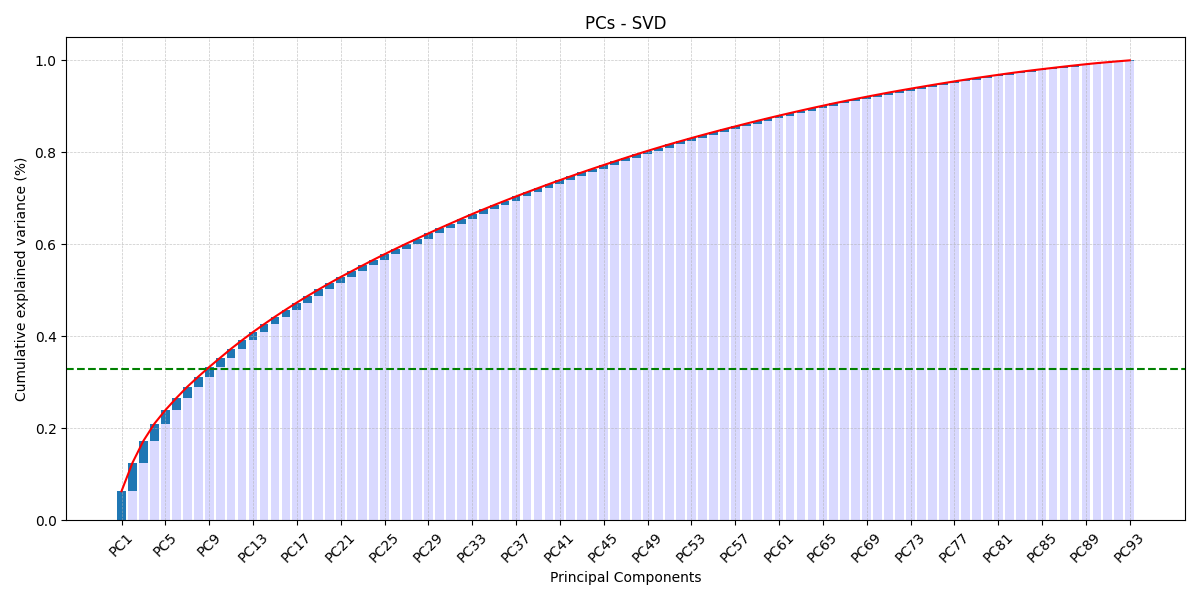

In [11]:
mu = np.mean(responses_ft_enc, axis=0)
sigma = np.std(responses_ft_enc, axis=0)
sigma[sigma == 0] = 1.0 # We eliminate the case where the variance is zero, which can lead to errors 
                        # (in this case x-mu would be 0 so the next step will be logically the same)
X_standardized = ((responses_ft_enc - mu) / sigma).to_numpy()

U, S, V = sing_val_dec(X_standardized)

s_squared = S**2 / (X_standardized.shape[0] - 1)
total_variance = np.sum(s_squared)
explained_variance_ratio = s_squared / total_variance

n_features = len(explained_variance_ratio)

plt.figure(figsize=(12, 6))
plt.bar(
    np.arange(n_features), 
    explained_variance_ratio, 
    bottom=np.insert(np.cumsum(explained_variance_ratio), 0, 0)[:-1]
)
plt.bar(
    np.arange(n_features), 
    np.insert(np.cumsum(explained_variance_ratio), 0, 0)[:-1], 
    color='b', 
    alpha=0.15
)
plt.plot(np.cumsum(explained_variance_ratio), 'r')
plt.axhline(y=0.33, color='g', linestyle='--')
plt.title('PCs - SVD')
plt.xticks(
    np.arange(n_features)[::4], 
    rotation=45, 
    labels=[f'PC{i}' for i in range(1, n_features + 1)][::4]
)
plt.xlabel('Principal Components')
plt.ylabel('Cumulative explained variance (%)')
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()

## Dimensionality Reduction 

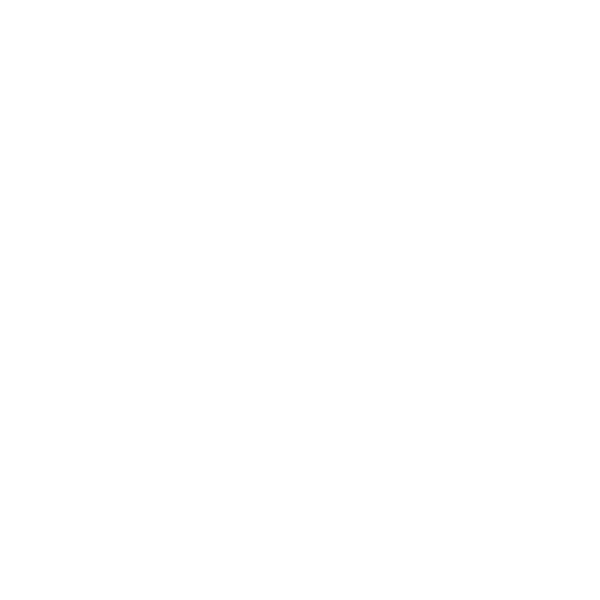

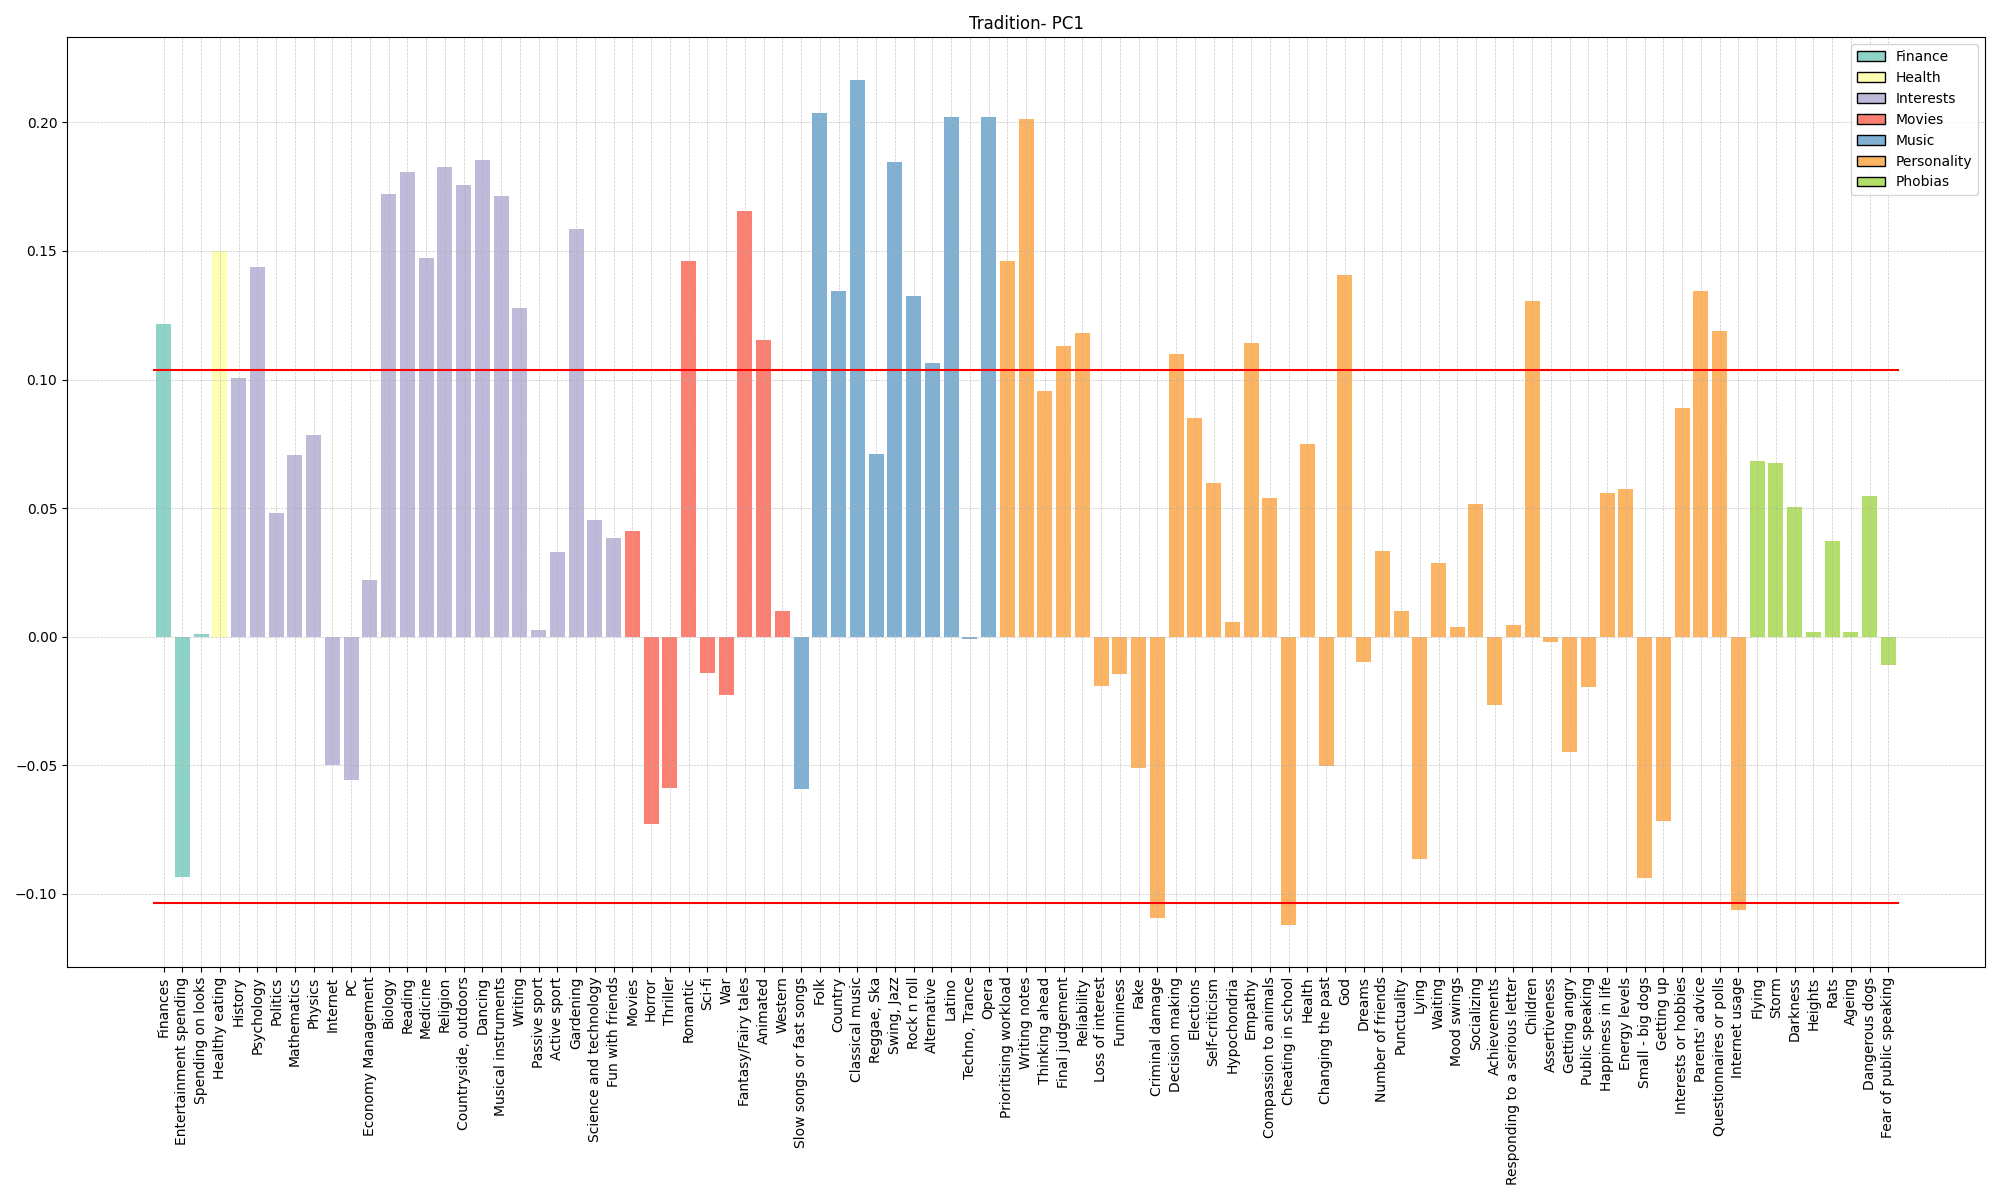


** PC1 **
HIGH-VALUED POSITIVE COMPONENTS: ['Classical music', 'Folk', 'Opera', 'Latino', 'Writing notes', 'Dancing', 'Swing, Jazz', 'Religion', 'Reading', 'Countryside, outdoors', 'Biology', 'Musical instruments', 'Fantasy/Fairy tales', 'Gardening', 'Healthy eating', 'Medicine', 'Romantic', 'Prioritising workload', 'Psychology', 'God', "Parents' advice", 'Country', 'Rock n roll', 'Children', 'Writing', 'Finances', 'Questionnaires or polls', 'Reliability', 'Animated', 'Empathy', 'Final judgement', 'Decision making', 'Alternative']

HIGH-VALUED NEGATIVE COMPONENTS: ['Cheating in school', 'Criminal damage', 'Internet usage']
*



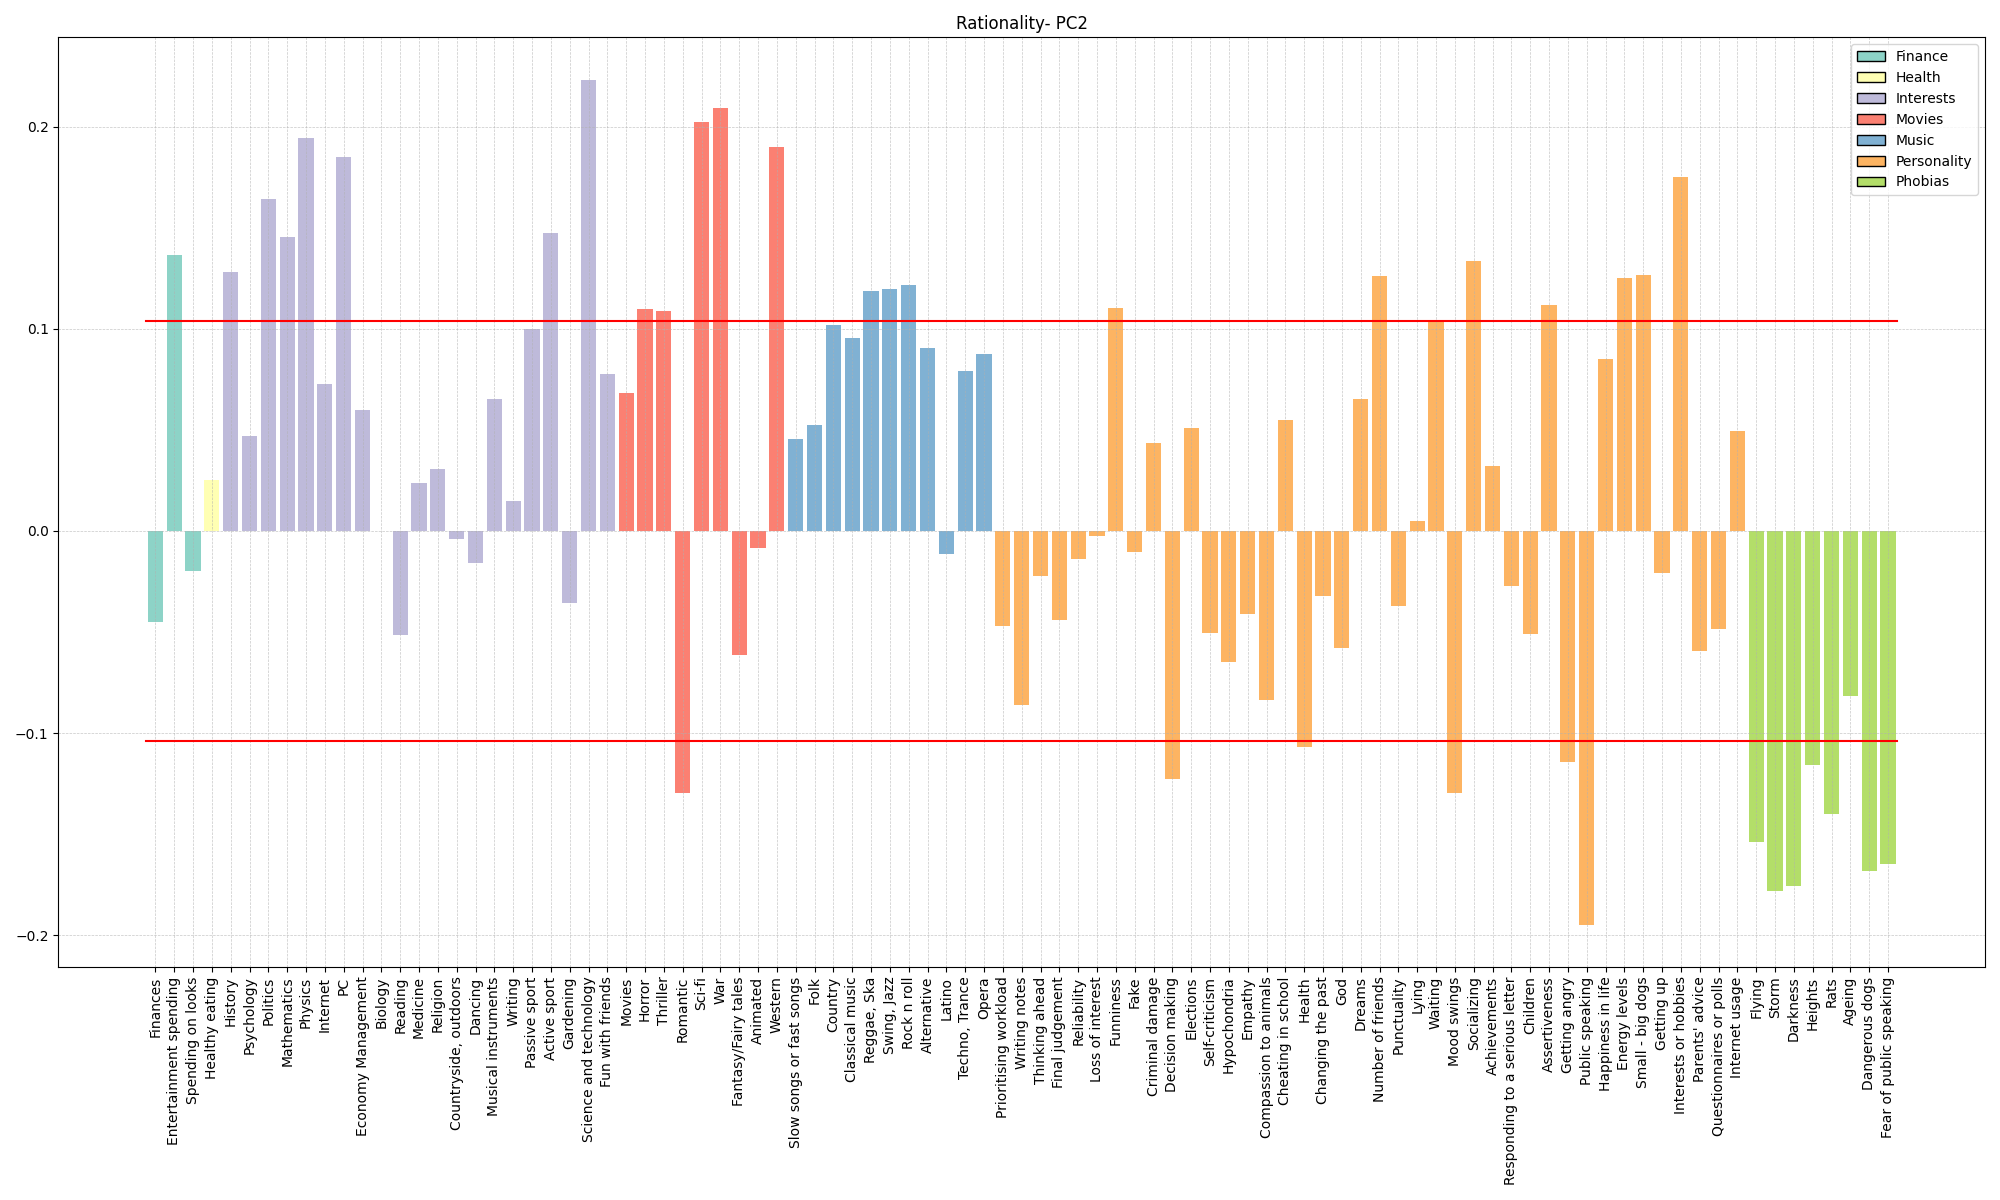


** PC2 **
HIGH-VALUED POSITIVE COMPONENTS: ['Science and technology', 'War', 'Sci-fi', 'Physics', 'Western', 'PC', 'Interests or hobbies', 'Politics', 'Active sport', 'Mathematics', 'Entertainment spending', 'Socializing', 'History', 'Small - big dogs', 'Number of friends', 'Energy levels', 'Rock n roll', 'Swing, Jazz', 'Reggae, Ska', 'Assertiveness', 'Funniness', 'Horror', 'Thriller', 'Waiting']

HIGH-VALUED NEGATIVE COMPONENTS: ['Public speaking', 'Storm', 'Darkness', 'Dangerous dogs', 'Fear of public speaking', 'Flying', 'Rats', 'Romantic', 'Mood swings', 'Decision making', 'Heights', 'Getting angry', 'Health']
*



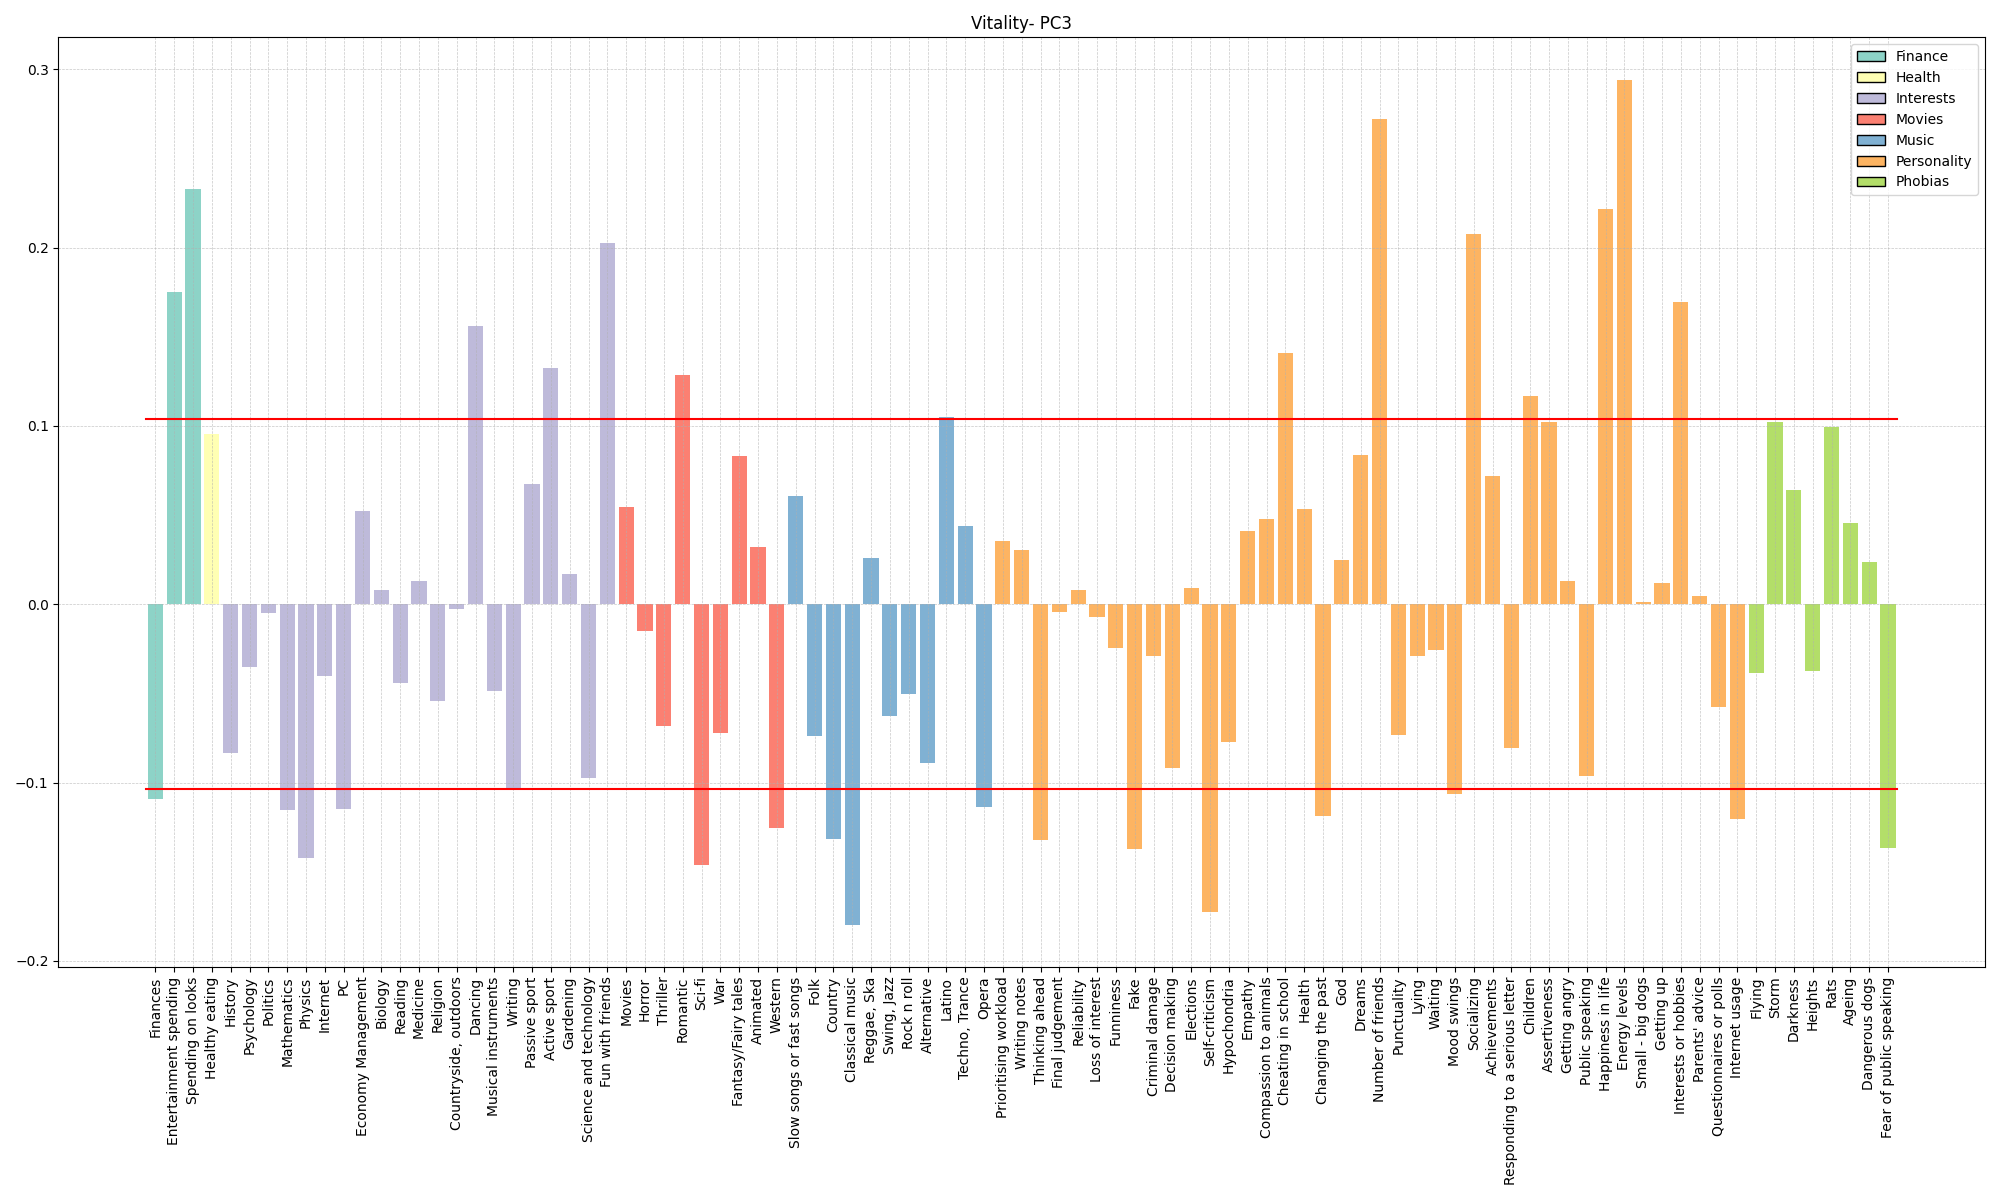


** PC3 **
HIGH-VALUED POSITIVE COMPONENTS: ['Energy levels', 'Number of friends', 'Spending on looks', 'Happiness in life', 'Socializing', 'Fun with friends', 'Entertainment spending', 'Interests or hobbies', 'Dancing', 'Cheating in school', 'Active sport', 'Romantic', 'Children', 'Latino']

HIGH-VALUED NEGATIVE COMPONENTS: ['Classical music', 'Self-criticism', 'Sci-fi', 'Physics', 'Fake', 'Fear of public speaking', 'Thinking ahead', 'Country', 'Western', 'Internet usage', 'Changing the past', 'Mathematics', 'PC', 'Opera', 'Finances', 'Mood swings', 'Writing']
*



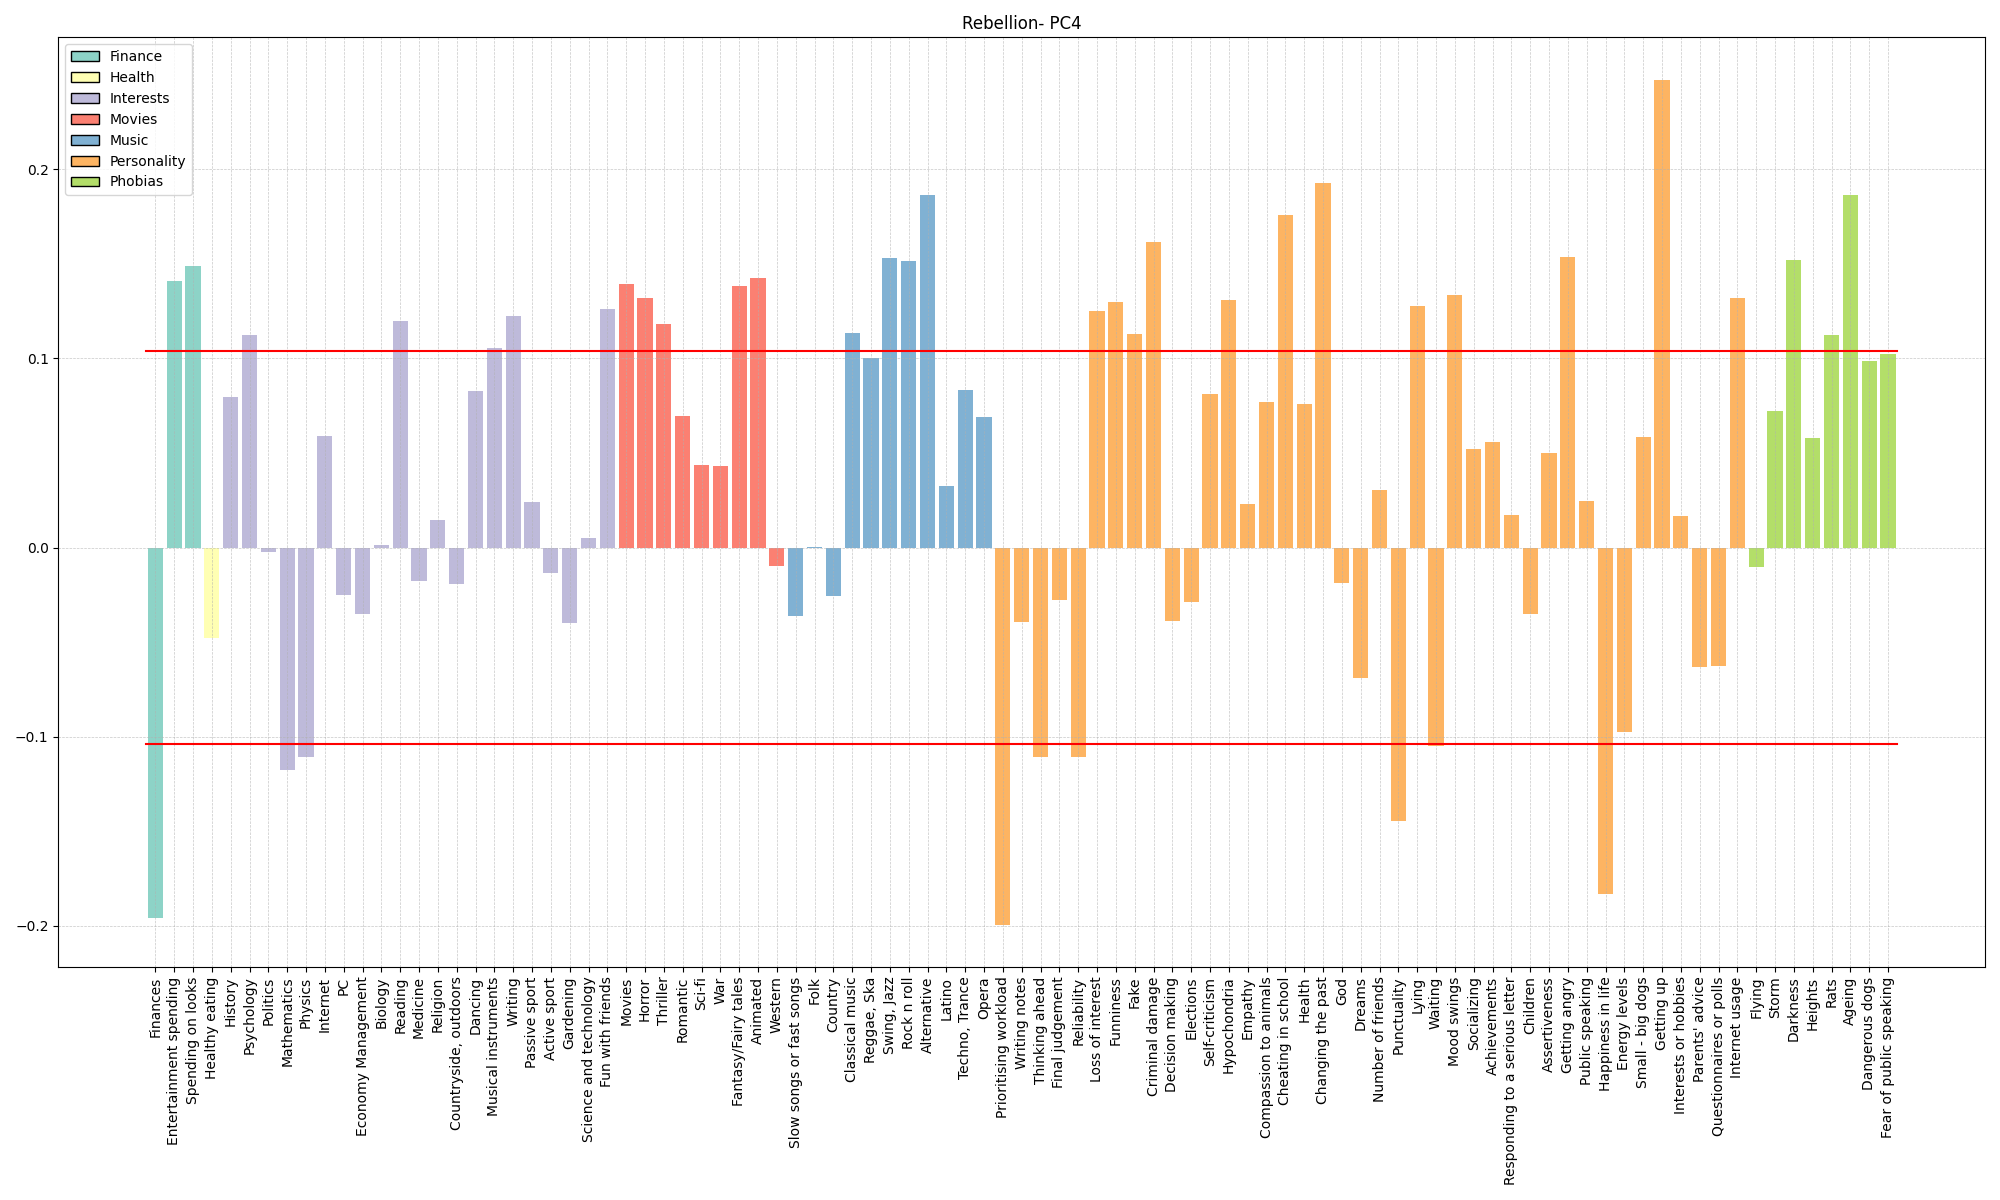


** PC4 **
HIGH-VALUED POSITIVE COMPONENTS: ['Getting up', 'Changing the past', 'Ageing', 'Alternative', 'Cheating in school', 'Criminal damage', 'Getting angry', 'Swing, Jazz', 'Darkness', 'Rock n roll', 'Spending on looks', 'Animated', 'Entertainment spending', 'Movies', 'Fantasy/Fairy tales', 'Mood swings', 'Internet usage', 'Horror', 'Hypochondria', 'Funniness', 'Lying', 'Fun with friends', 'Loss of interest', 'Writing', 'Reading', 'Thriller', 'Classical music', 'Fake', 'Rats', 'Psychology', 'Musical instruments']

HIGH-VALUED NEGATIVE COMPONENTS: ['Prioritising workload', 'Finances', 'Happiness in life', 'Punctuality', 'Mathematics', 'Physics', 'Reliability', 'Thinking ahead', 'Waiting']
*



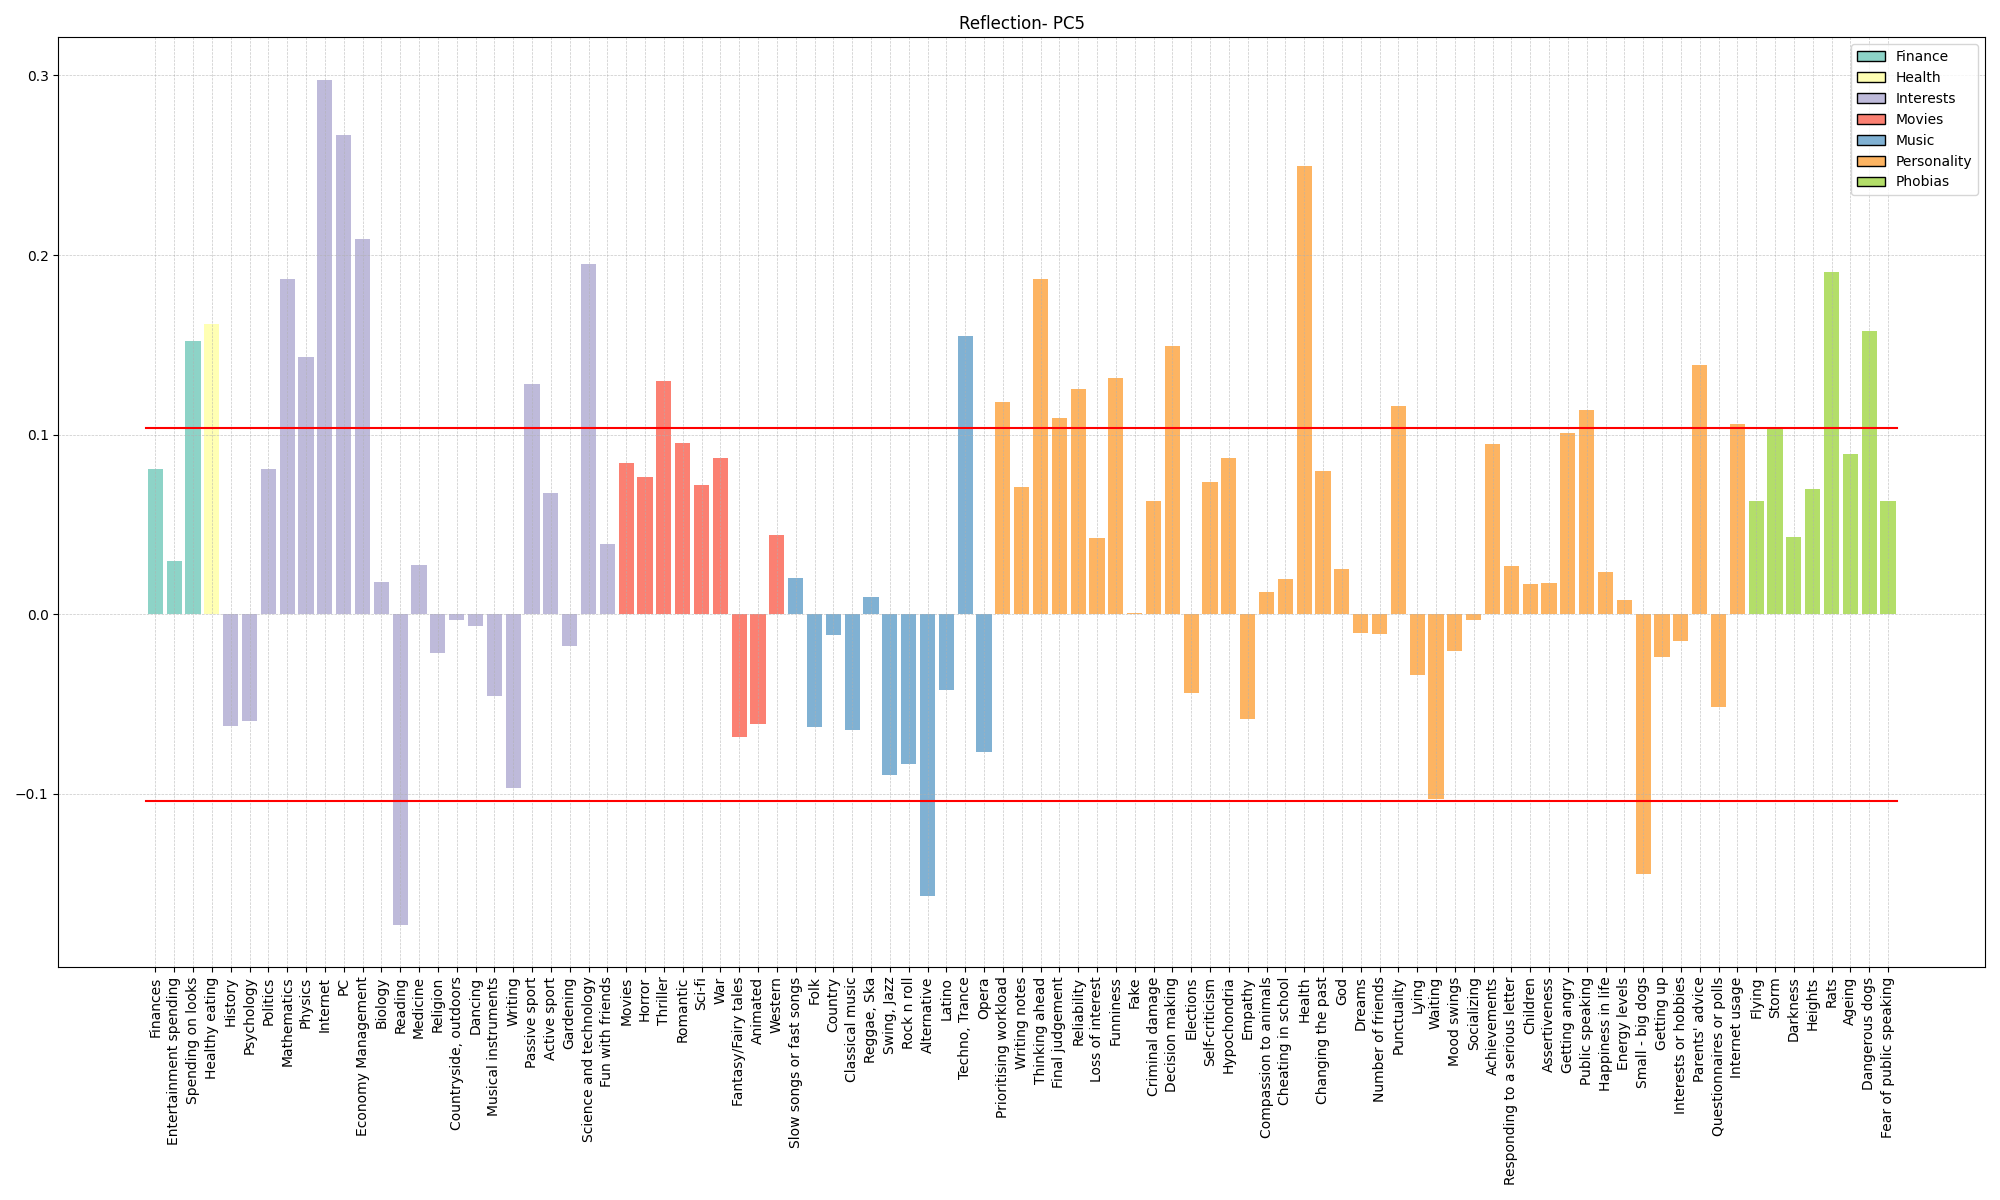


** PC5 **
HIGH-VALUED POSITIVE COMPONENTS: ['Internet', 'PC', 'Health', 'Economy Management', 'Science and technology', 'Rats', 'Thinking ahead', 'Mathematics', 'Healthy eating', 'Dangerous dogs', 'Techno, Trance', 'Spending on looks', 'Decision making', 'Physics', "Parents' advice", 'Funniness', 'Thriller', 'Passive sport', 'Reliability', 'Prioritising workload', 'Punctuality', 'Public speaking', 'Final judgement', 'Internet usage', 'Storm']

HIGH-VALUED NEGATIVE COMPONENTS: ['Reading', 'Alternative', 'Small - big dogs']
*



In [12]:
# We take the top m = 5 components
expl_var_ratio_m = explained_variance_ratio[:5]
if V.shape[0] == X_standardized.shape[1]: 
    components_m = V[:, :5].T
else:
    components_m = V[:5, :]
n_features = X_standardized.shape[1]

round_expl_var_ratio = np.round(expl_var_ratio_m.sum() * 100, decimals=2)
eps = np.sqrt(1 / n_features)

for i in range(V.shape[1]):
    component = V[:, i]
    
    max_abs_idx = np.argmax(np.abs(component))
    sign = np.sign(component[max_abs_idx])
    if sign < 0:
        V[:, i] *= -1
        U[:, i] *= -1


pc_names = [
    'Tradition',
    'Rationality',
    'Vitality',          
    'Rebellion',
    'Reflection'
]
plt.figure(figsize=(6, 6))
plt.bar(range(1, 6), expl_var_ratio_m, color='skyblue')
plt.title(f"PCs EXPLAINED VARIANCE ({round_expl_var_ratio}% OF TOT. EXPL. VAR.)")
plt.xticks(
    ticks=np.arange(1, 6),
    labels=[f'{pc_names[i-1]}' for i in range(1, 6)],
    rotation=45
)
plt.xlabel('Principal Components')
plt.ylabel('Percentage of Explained Variance')
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()


current_names = pc_names[:5] if 5 <= len(pc_names) else [f'PC{i+1}' for i in range(5)]

for i in range(5):
    plt.figure(figsize=(20, 12))
    
    component_values = components_m[i, :]
    
    plt.bar(
        np.arange(n_features),
        component_values,
        color=colors_type 
    )

    plt.plot([-0.5, n_features - 0.5], [eps, eps], 'red')
    plt.plot([-0.5, n_features - 0.5], [-eps, -eps], 'red')

    plt.xticks(
        ticks=np.arange(n_features),
        labels=features, 
        rotation=90
    )

    pc_label = pc_names[i] if i < len(pc_names) else f'PC{i+1}'
    plt.title(f'{pc_label}- PC{i + 1}')
    
    plt.legend(handles=type_legendelements) 
    plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
    plt.tight_layout()
    plt.show()
    ind_great_pos = np.argwhere(component_values >= eps).flatten()
    ind_great_neg = np.argwhere(component_values <= -eps).flatten()

    vals_pos = component_values[ind_great_pos]
    vals_neg = component_values[ind_great_neg]
    
    sorted_ind_pos = ind_great_pos[np.argsort(vals_pos)[::-1]]
    sorted_ind_neg = ind_great_neg[np.argsort(vals_neg)]
    
    great_pos_PCi = [features[idx] for idx in sorted_ind_pos]
    great_neg_PCi = [features[idx] for idx in sorted_ind_neg]
    
    print('')
    print('**', f'PC{i+1}', '**')
    print(f'HIGH-VALUED POSITIVE COMPONENTS: {great_pos_PCi}')
    print('')
    print(f'HIGH-VALUED NEGATIVE COMPONENTS: {great_neg_PCi}')
    print('*')
    print('')

#### Score graph

,Tradition,Rationality,Vitality,Rebellion,Reflection
0,1.662530,0.968691,-2.892800,-2.091868,2.383666
1,-2.690156,-2.755514,3.988395,-1.445670,2.408639
2,-6.079840,-1.310221,-1.407343,-0.092512,0.984659
3,0.713516,0.835471,0.055386,3.463530,-0.479180
4,1.435500,0.708105,2.192272,-2.791261,-0.681575


C:\Users\davep\AppData\Local\Temp\ipykernel_27320\1527450845.py:15: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


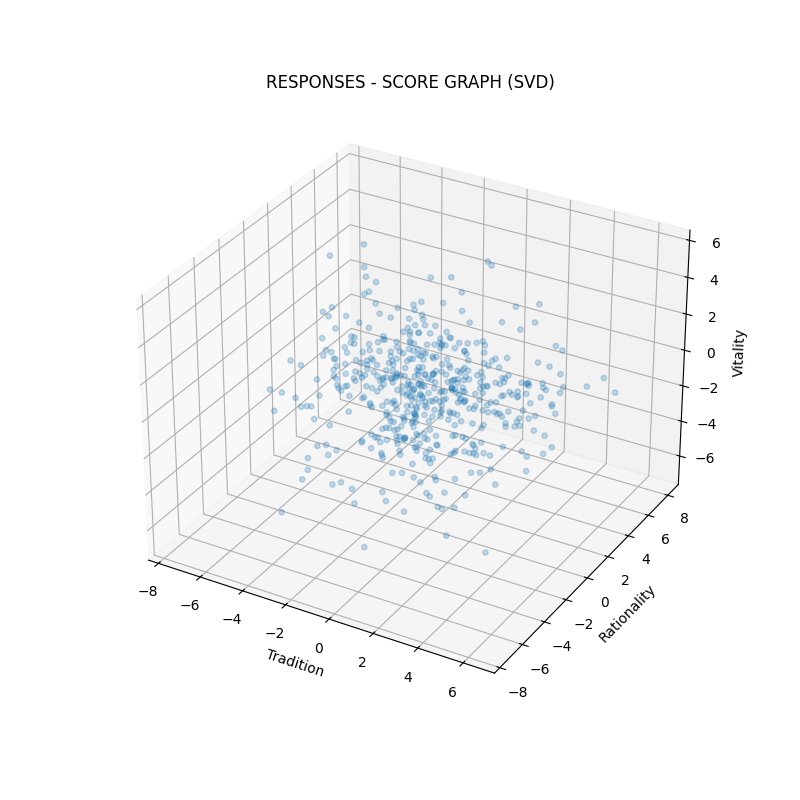

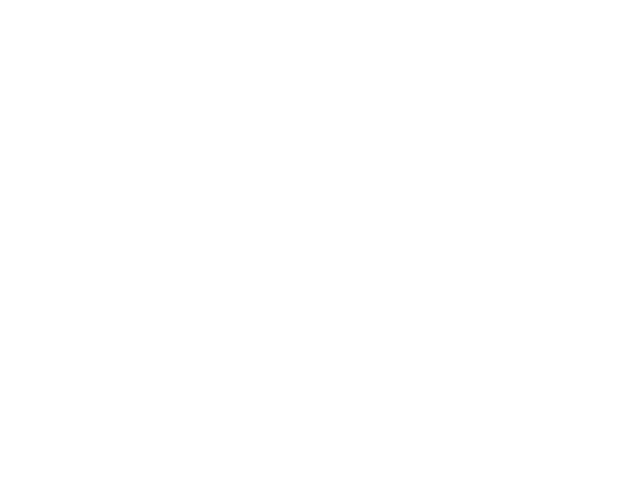

In [13]:
scores = U[:, :5]*S[:5]
scores_df = pd.DataFrame(scores, columns=pc_names[:5])
display(scores_df.head())

sg_3d = plt.figure(figsize=(8, 8))
ax_3d = sg_3d.add_subplot(111, projection='3d')

ax_3d.scatter(scores[:, 0], scores[:, 1], scores[:, 2], s=15, alpha=0.25)
ax_3d.set_title('RESPONSES - SCORE GRAPH (SVD)')

ax_3d.set_xlabel(pc_names[0])
ax_3d.set_ylabel(pc_names[1])
ax_3d.set_zlabel(pc_names[2])
ax_3d.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()

plt.figure()
plt.scatter(scores[:, 0], scores[:, 1], s=15, alpha=0.25)
plt.title('RESPONSES - SCORE GRAPH (SVD - PROJ. ON R^2)')

plt.xlabel(pc_names[0])
plt.ylabel(pc_names[1])

plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()

## $k$-Means

** STARTING ANALYSIS **

Processing k=3...
   Silhouette Score: 0.1749
Processing k=4...
   Silhouette Score: 0.1694
Processing k=5...
   Silhouette Score: 0.1761
Processing k=6...
   Silhouette Score: 0.1709
Processing k=7...
   Silhouette Score: 0.1647
Processing k=8...
   Silhouette Score: 0.1569
Processing k=9...
   Silhouette Score: 0.1612
Processing k=10...
   Silhouette Score: 0.1525

** ANALYSIS COMPLETE **
Best k: 5 with score: 0.1761


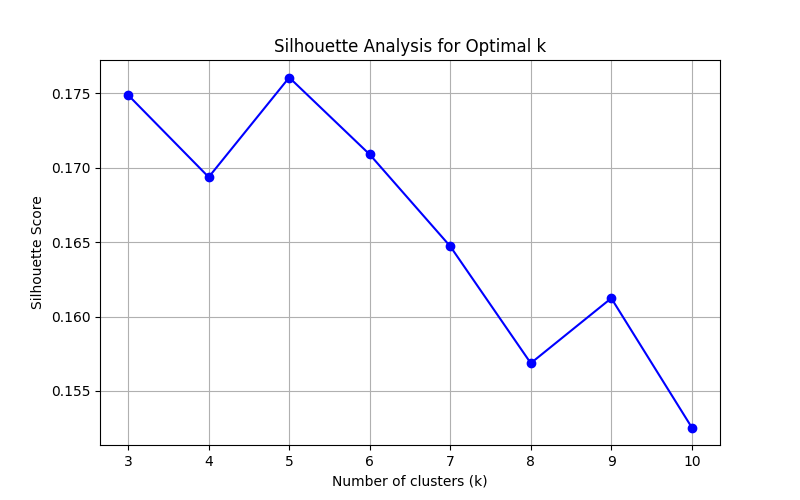

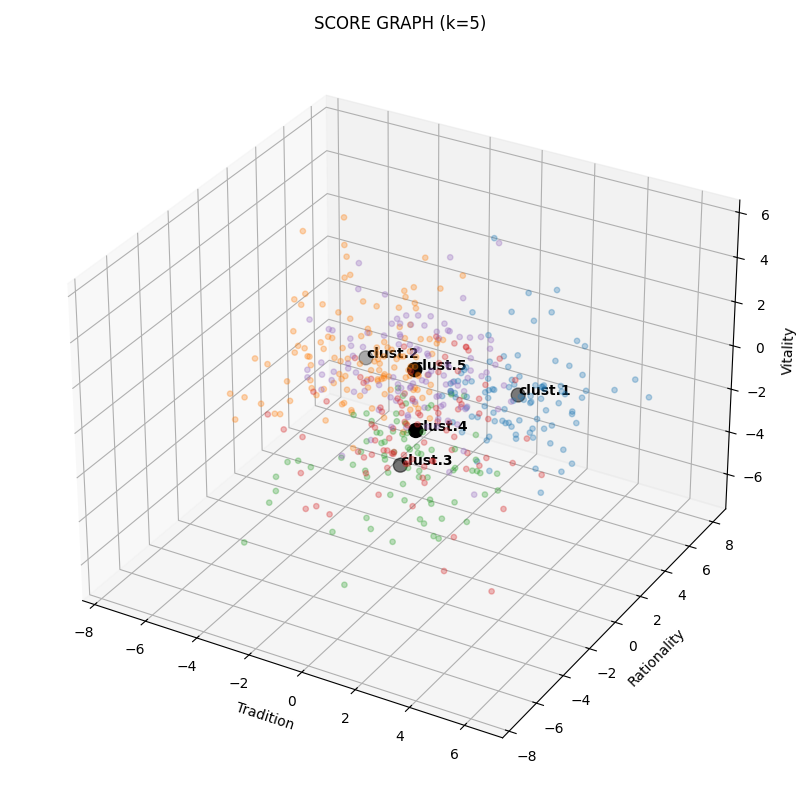

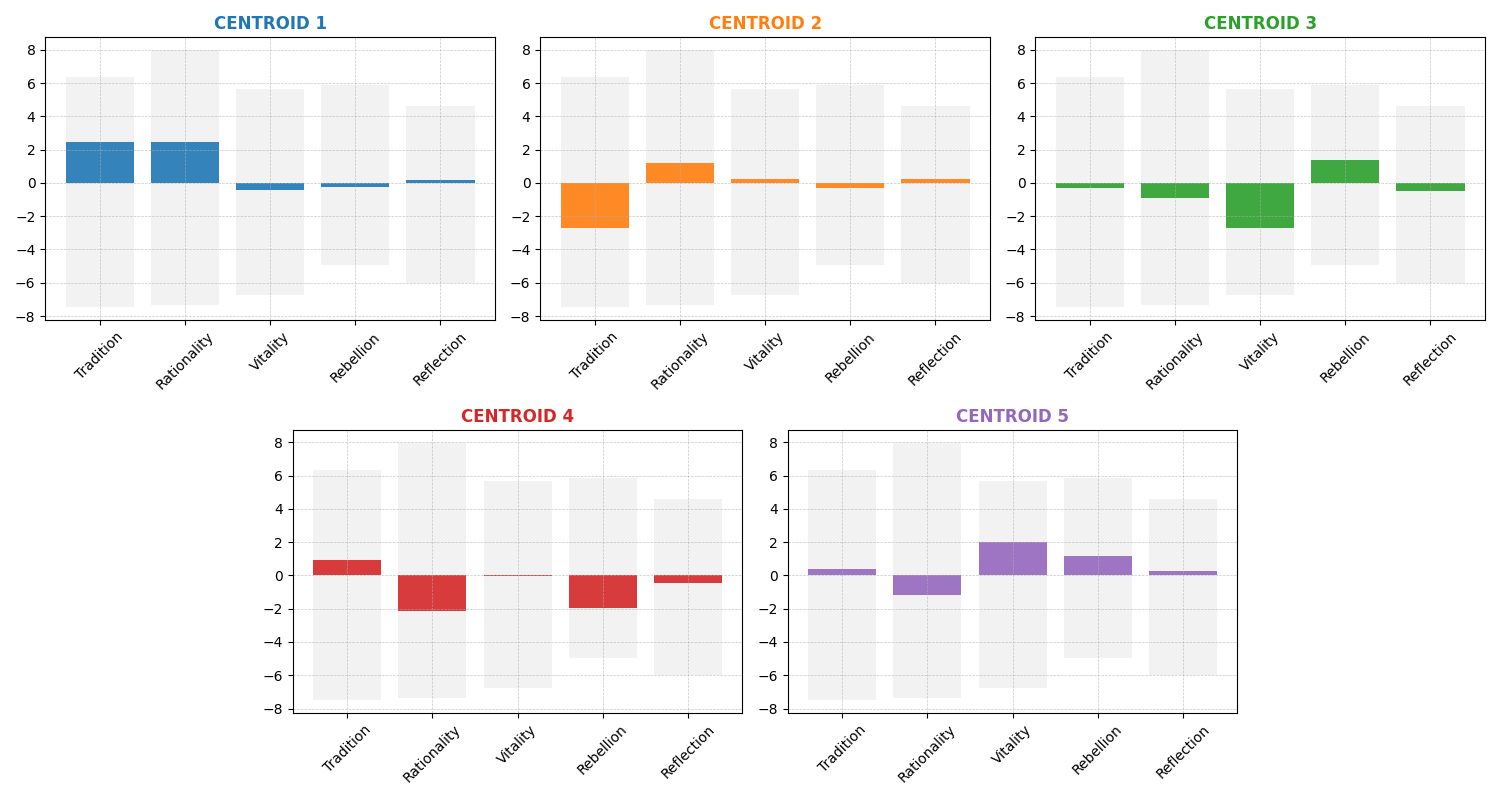

In [14]:
m = -np.inf
k_range = range(3, 11)
k_best = 0
silhouette_scores = []  

print('** STARTING ANALYSIS **\n')

for k in k_range:
    print(f'Processing k={k}...')
    km = KMeans(n_clusters=k, random_state=random_seed)
    km.fit(scores)
    
    silcoeff = silhouette_score(scores, km.labels_)
    silhouette_scores.append(silcoeff) # Store the score
    
    if silcoeff > m:
        k_best = k
        m = silcoeff

    print(f'   Silhouette Score: {silcoeff:.4f}')

print('\n** ANALYSIS COMPLETE **')
print(f'Best k: {k_best} with score: {m:.4f}')


plt.figure(figsize=(8, 5))
plt.plot(k_range, silhouette_scores, marker='o', linestyle='-', color='b')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Analysis for Optimal k')
plt.grid(True)
plt.xticks(k_range) 
plt.show()


cmap = plt.cm.tab10 
km = KMeans(n_clusters=k_best, random_state=random_seed)
km.fit(scores)
sg_3d_km = plt.figure(figsize=(8, 8))
ax_3d_km = sg_3d_km.add_subplot(111, projection='3d')
ax_3d_km.scatter(scores[:, 0], scores[:, 1], scores[:, 2], s=15, c=cmap(km.labels_), alpha=0.3)

ax_3d_km.scatter(
    km.cluster_centers_[:, 0],
    km.cluster_centers_[:, 1],
    km.cluster_centers_[:, 2],
    c='black',
    s=100, 
    marker='o' 
)

for kk in range(k_best):
    ax_3d_km.text(
        km.cluster_centers_[kk, 0],
        km.cluster_centers_[kk, 1],
        km.cluster_centers_[kk, 2],
        f'clust.{kk + 1}',
        fontsize=10,
        fontweight='bold'
    )

ax_3d_km.set_title(f'SCORE GRAPH (k={k_best})')
ax_3d_km.set_xlabel(pc_names[0])
ax_3d_km.set_ylabel(pc_names[1])
ax_3d_km.set_zlabel(pc_names[2])
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
plt.tight_layout()
plt.show()


maxs_y = scores.max(axis=0)
mins_y = scores.min(axis=0)

fig = plt.figure(figsize=(15, 8))
gs = fig.add_gridspec(2, 6)

axes = []
axes.append(fig.add_subplot(gs[0, 0:2])) 
axes.append(fig.add_subplot(gs[0, 2:4])) 
axes.append(fig.add_subplot(gs[0, 4:6])) 

axes.append(fig.add_subplot(gs[1, 1:3])) 
axes.append(fig.add_subplot(gs[1, 3:5])) 

for ii in range(k_best):
    ax = axes[ii]
    cluster_color = cmap(ii)

    ax.bar(np.arange(km.cluster_centers_.shape[1]), maxs_y, color='gray', alpha=0.1)
    ax.bar(np.arange(km.cluster_centers_.shape[1]), mins_y, color='gray', alpha=0.1)

    ax.bar(
        np.arange(km.cluster_centers_.shape[1]),
        km.cluster_centers_[ii, :],
        color=cluster_color, 
        alpha=0.9
    )

    ax.set_xticks(ticks=np.arange(km.cluster_centers_.shape[1]))
    ax.set_xticklabels(labels=pc_names, rotation=45)
    ax.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)
    ax.set_title(f'CENTROID {ii + 1}', color=cluster_color, fontweight='bold')

plt.tight_layout()
plt.show()

## Cluster External Evaluations

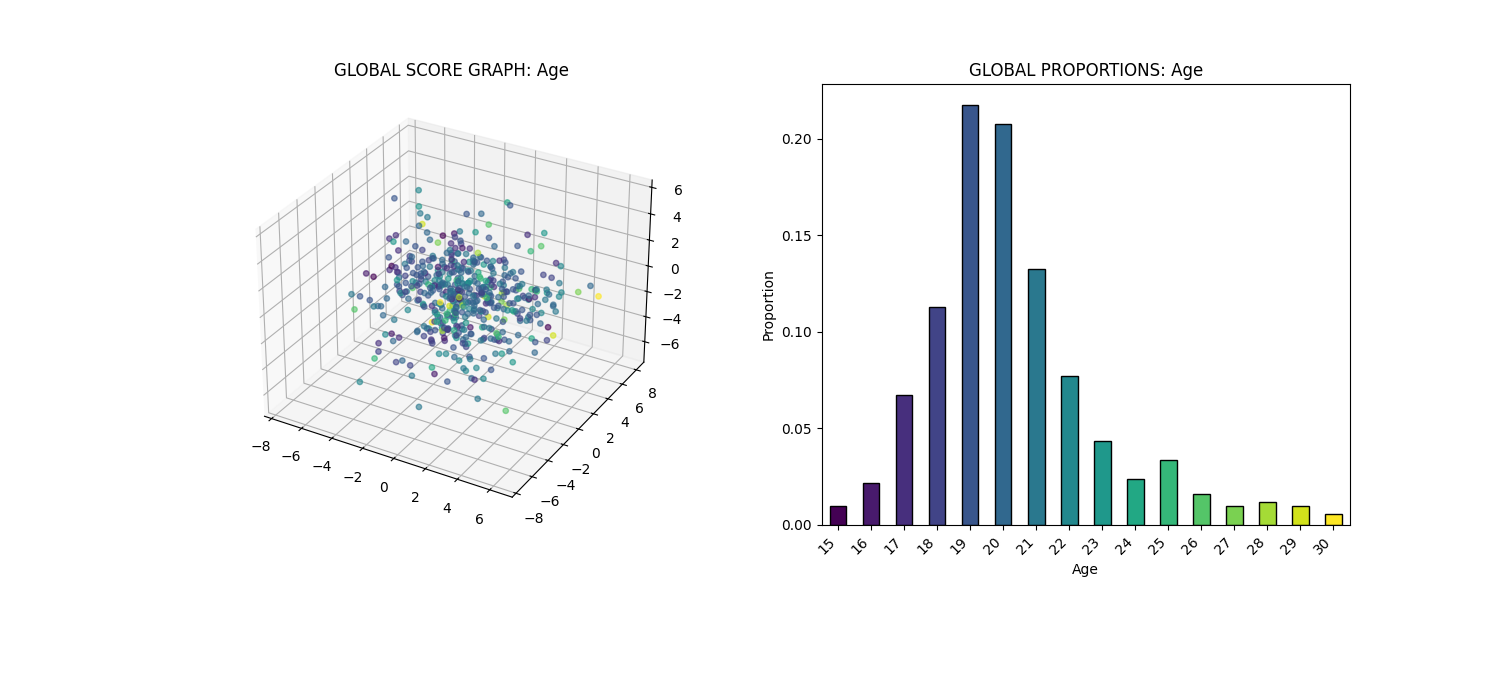

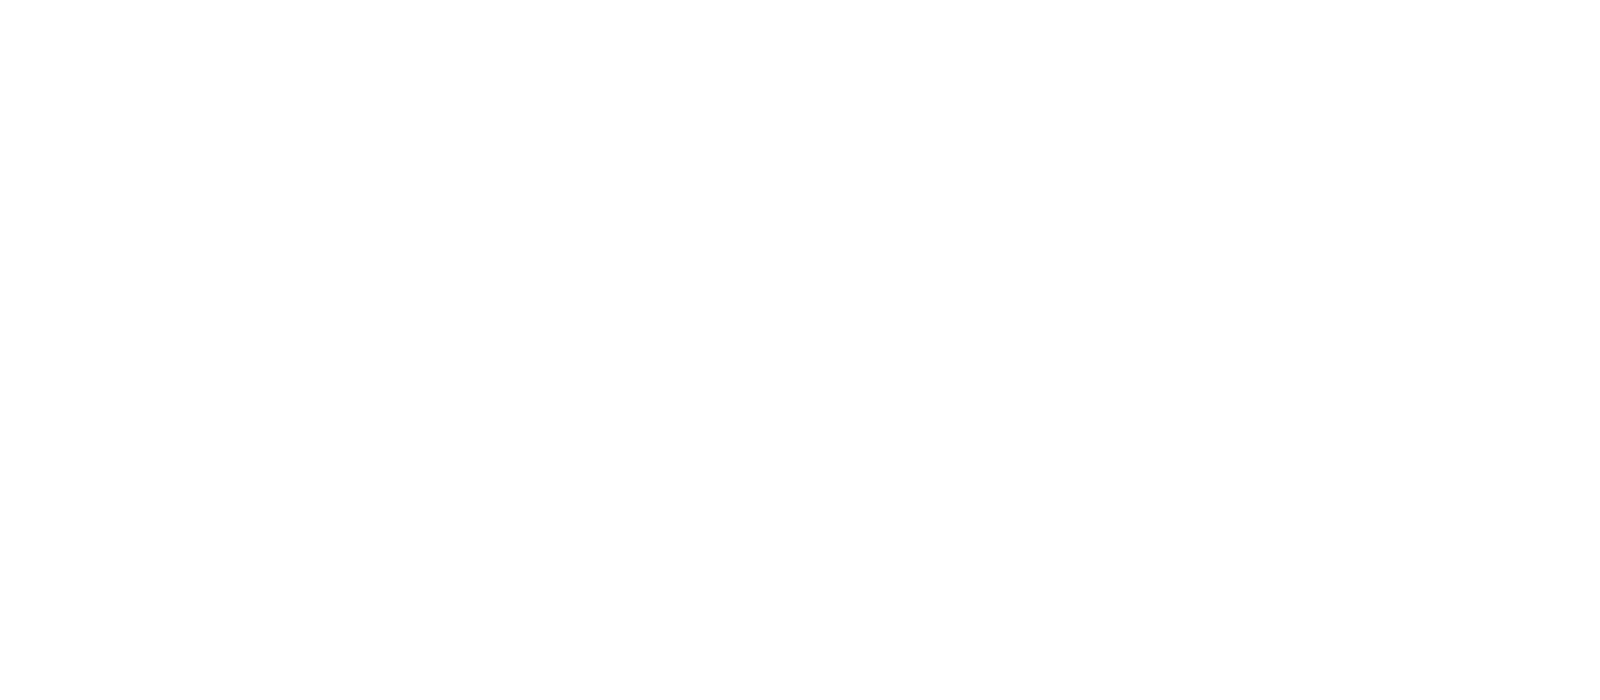

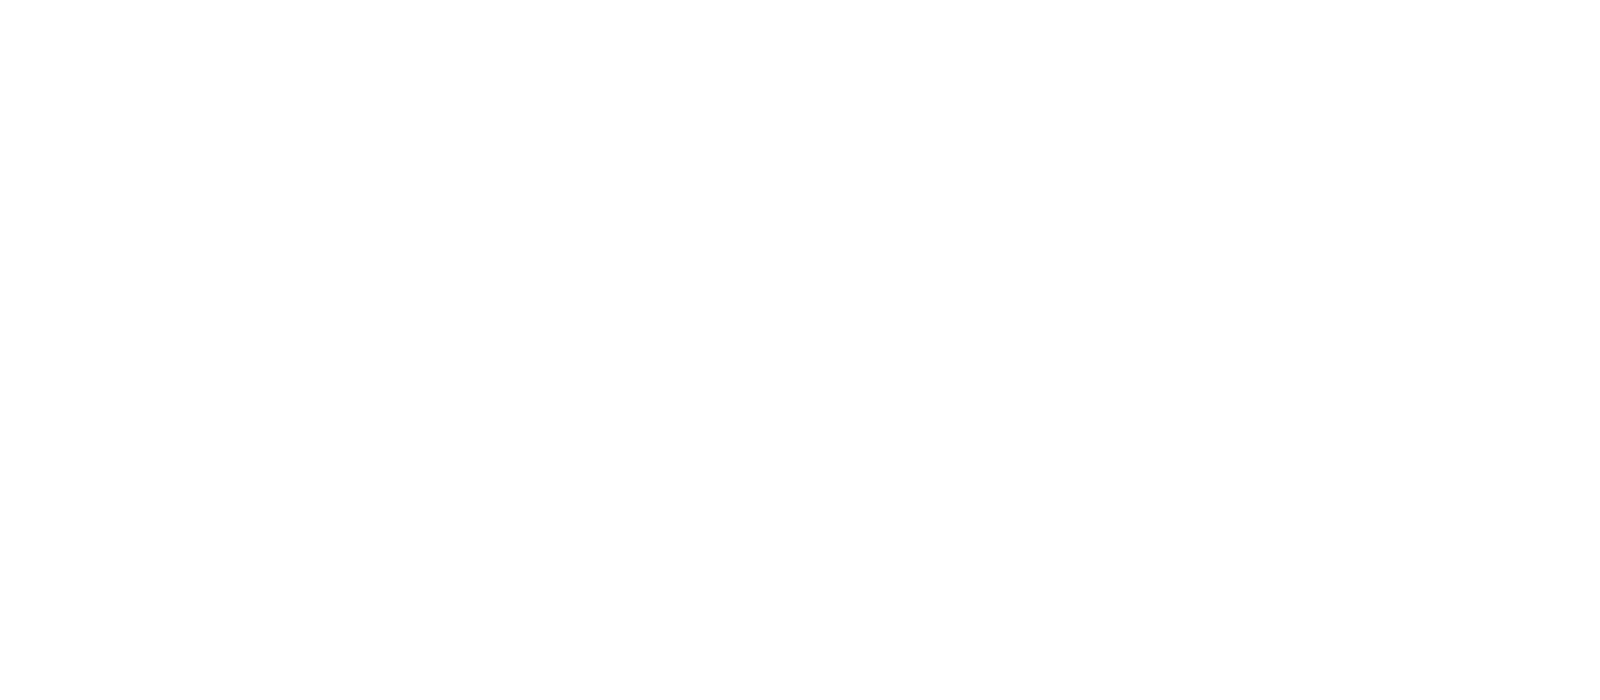

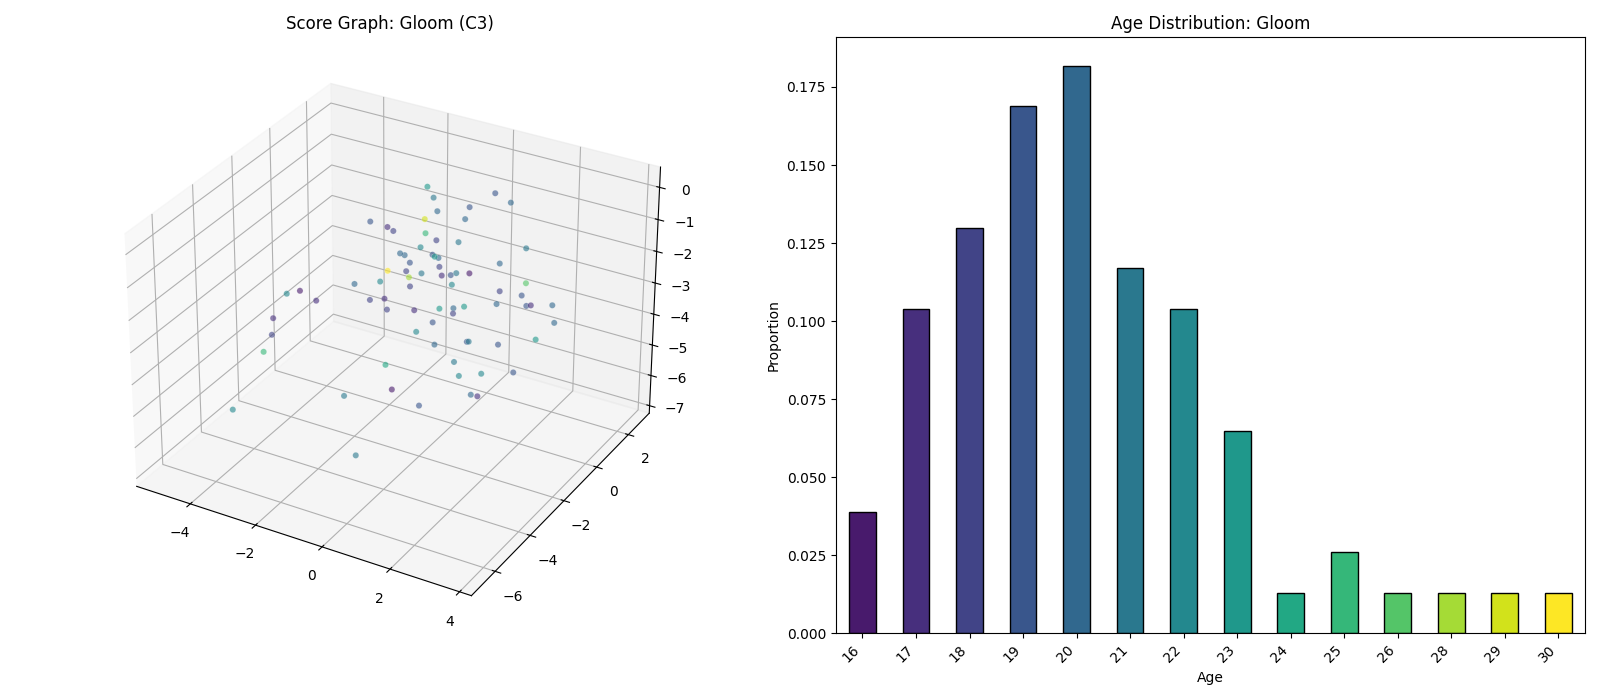

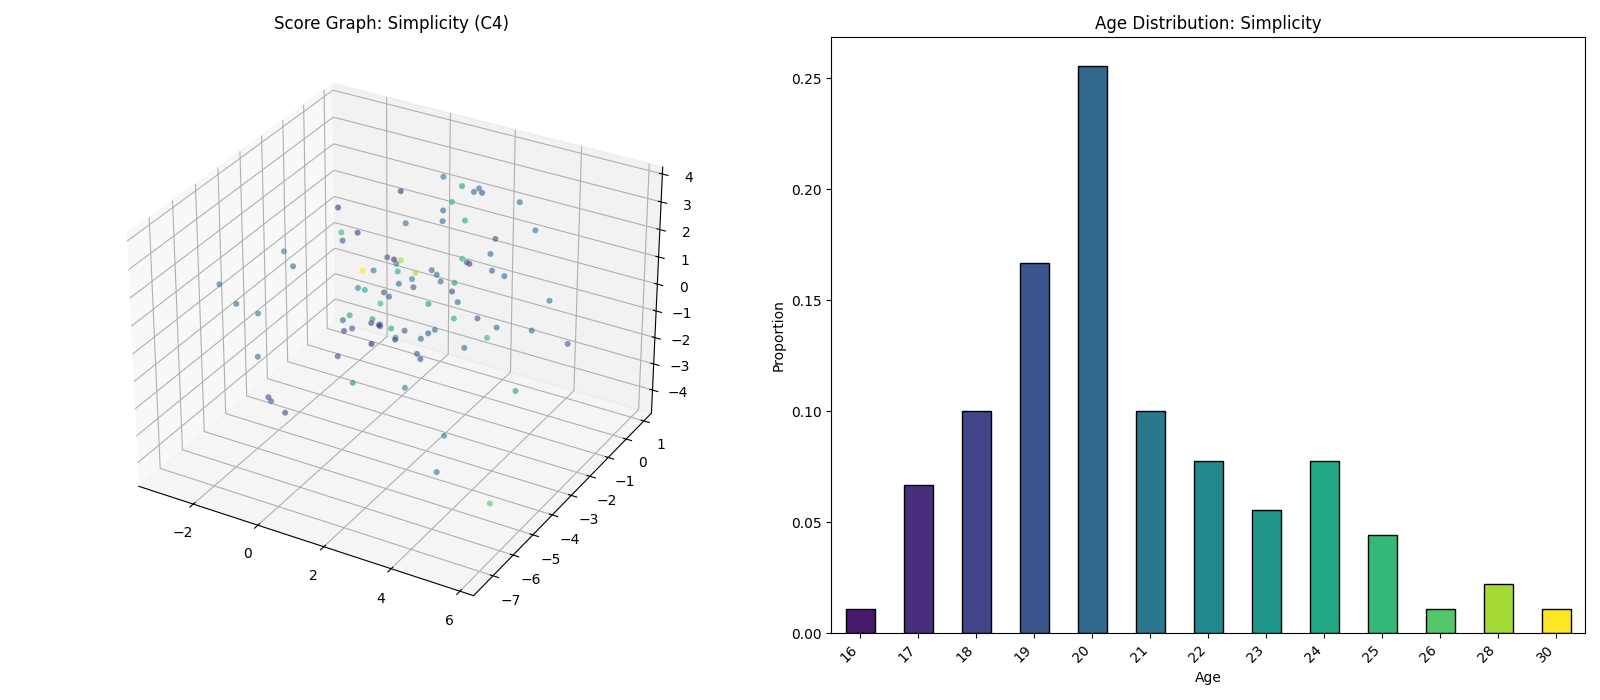

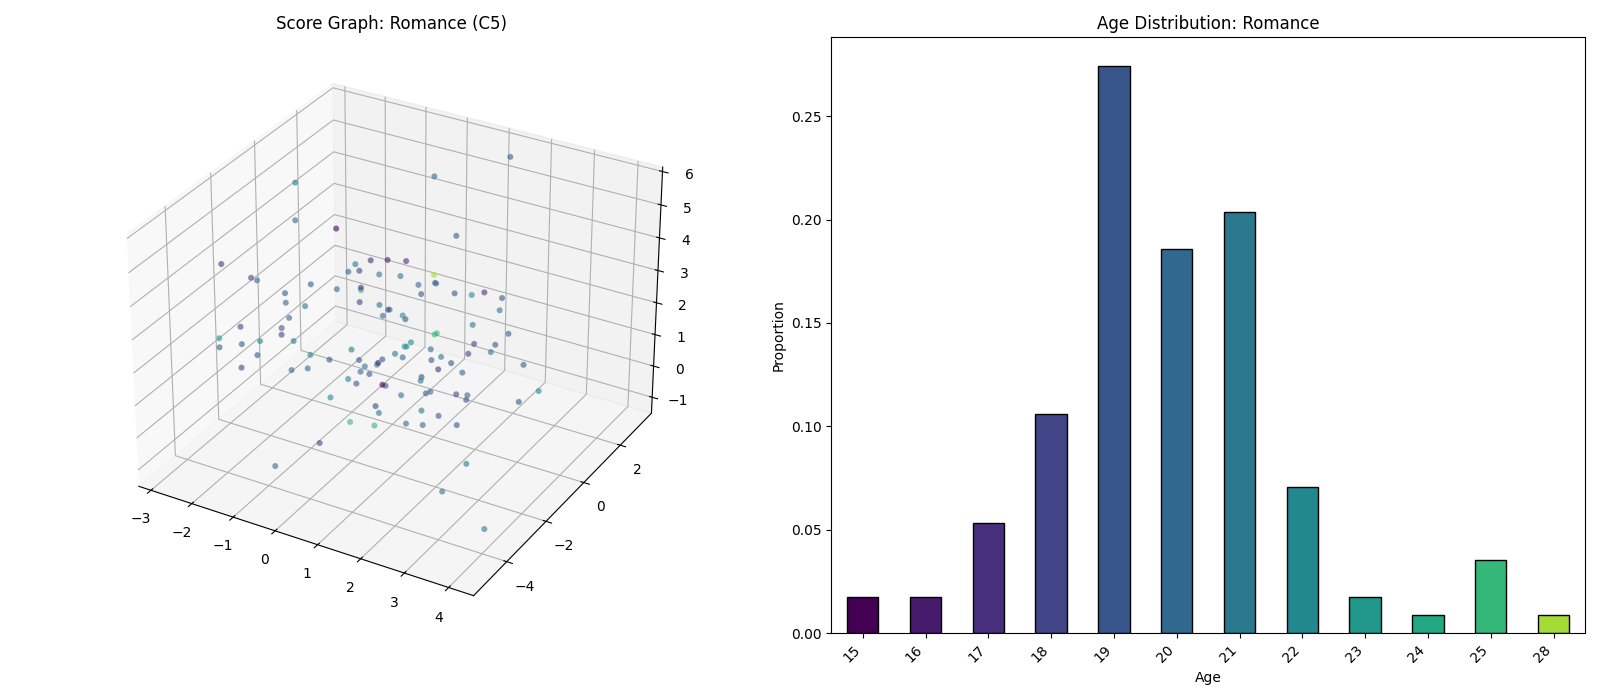

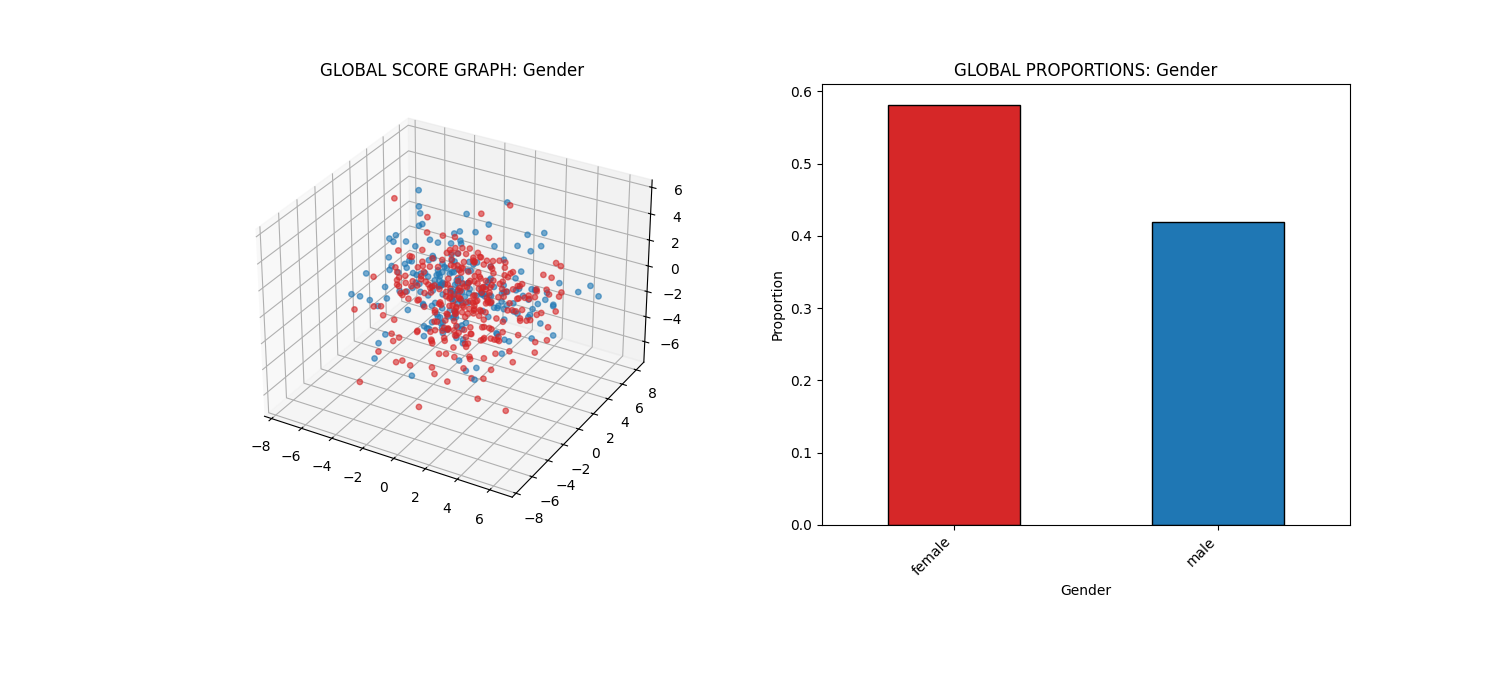

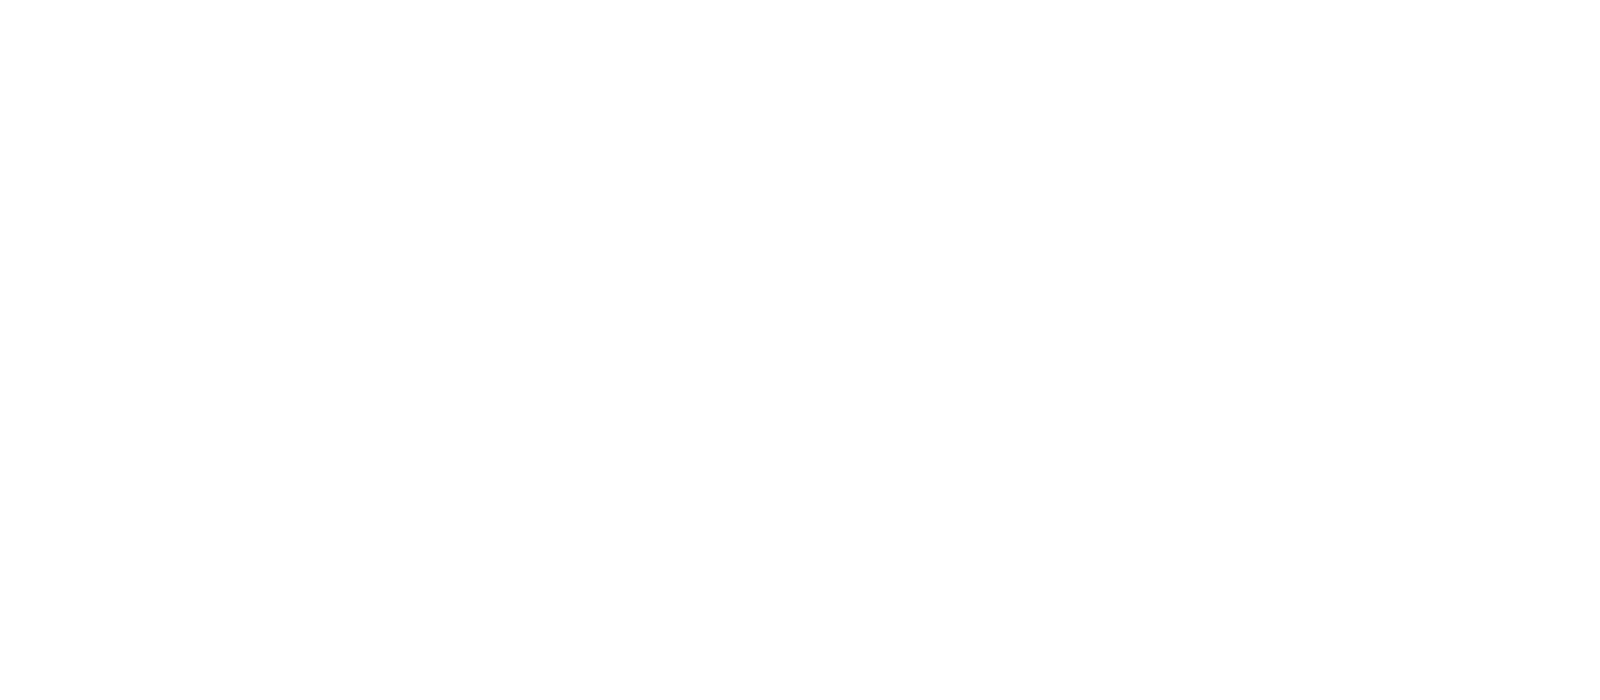

C:\Users\davep\AppData\Local\Temp\ipykernel_27320\1297084120.py:51: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig_cluster = plt.figure(figsize=(16, 7))


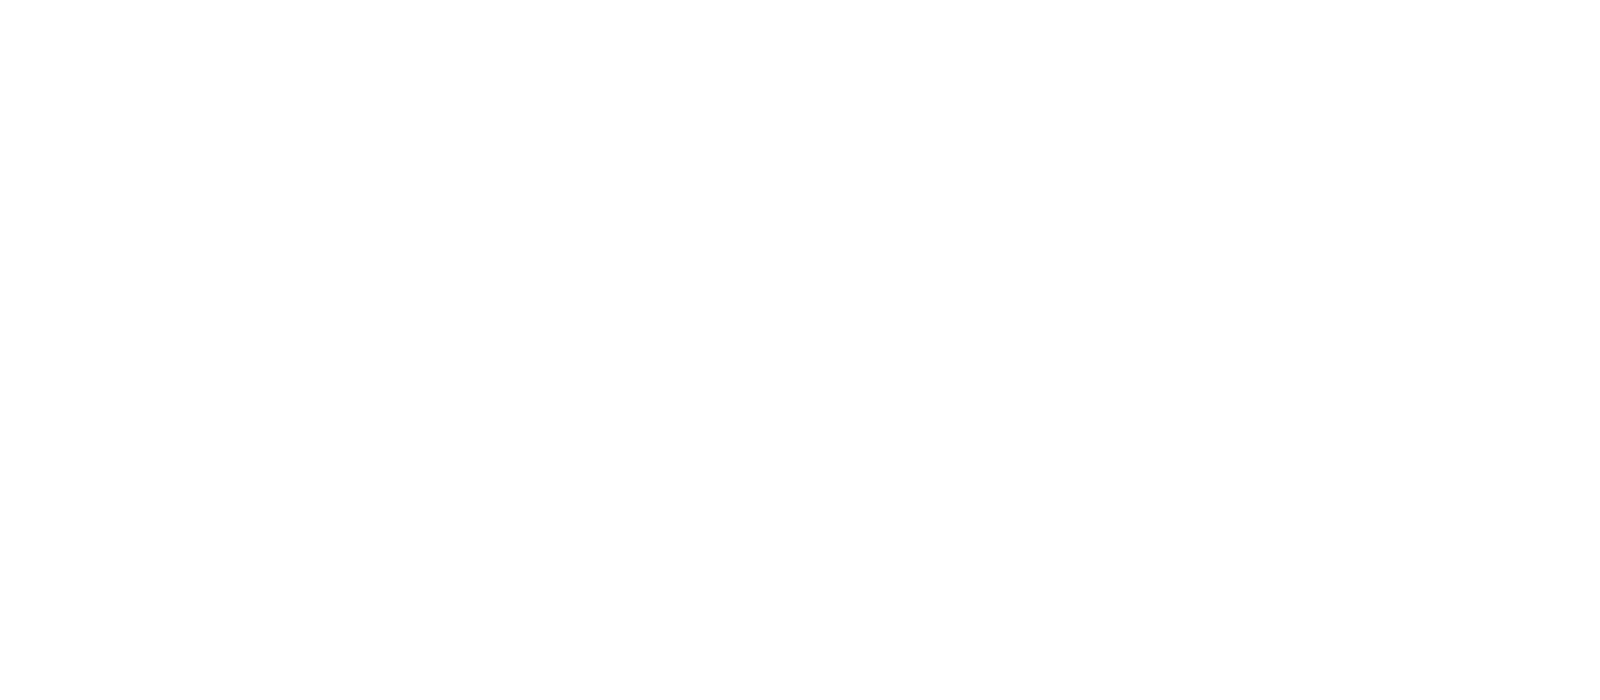

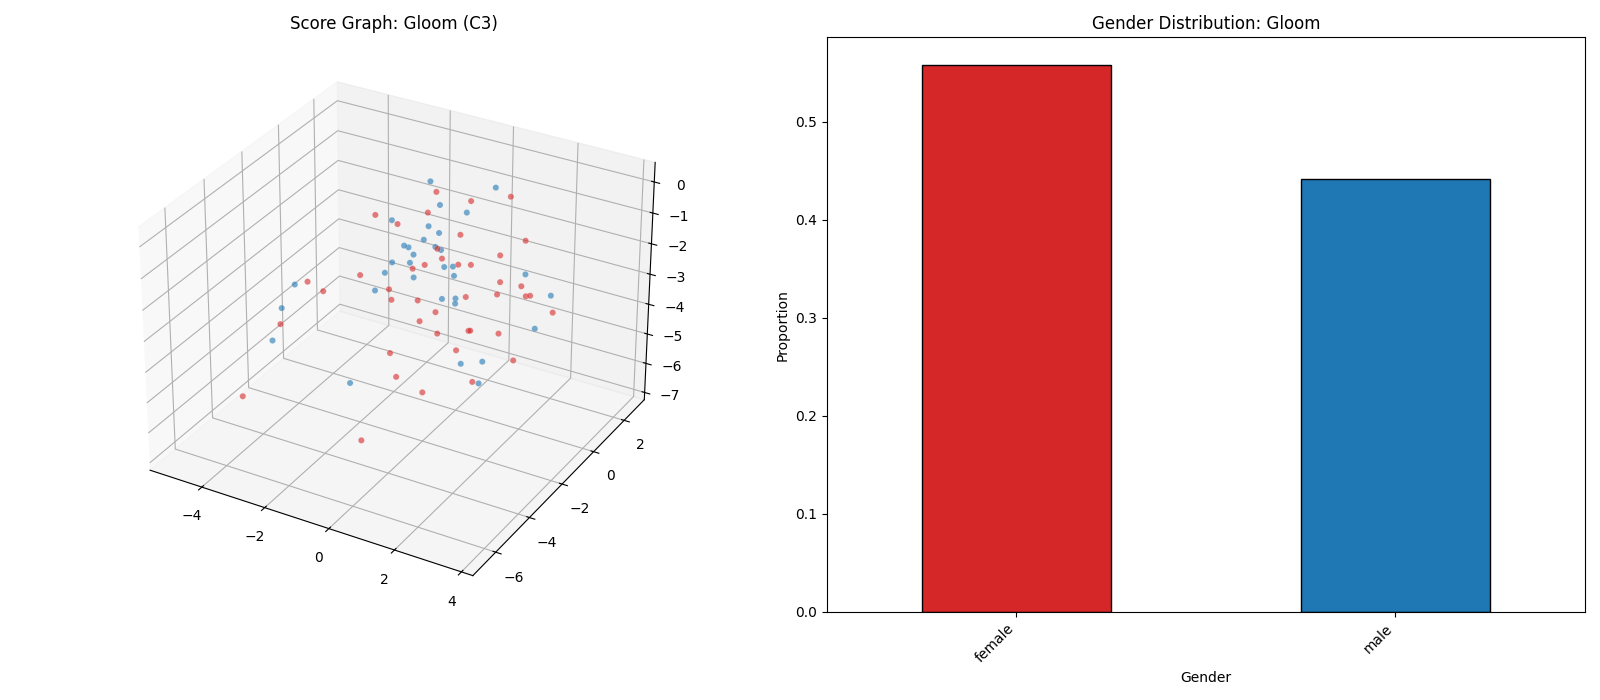

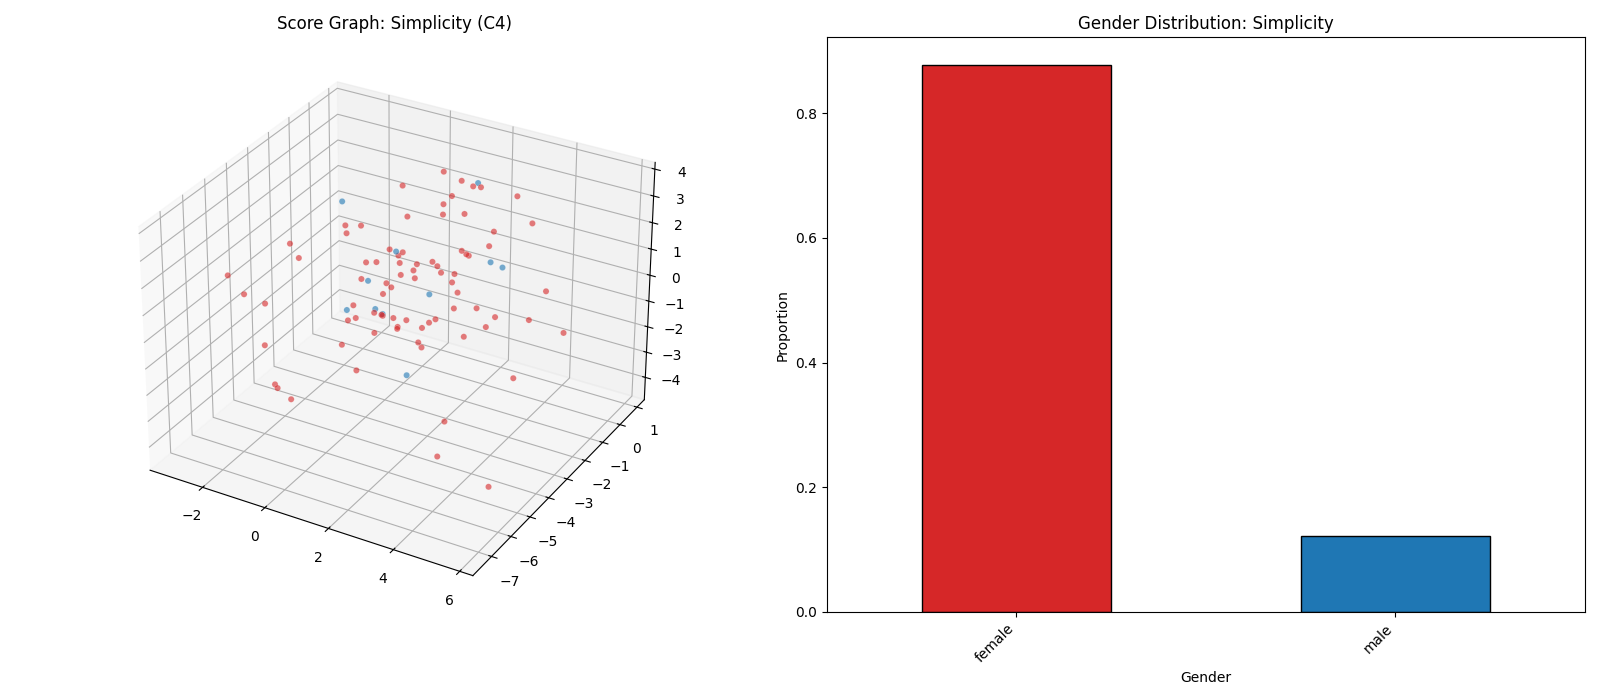

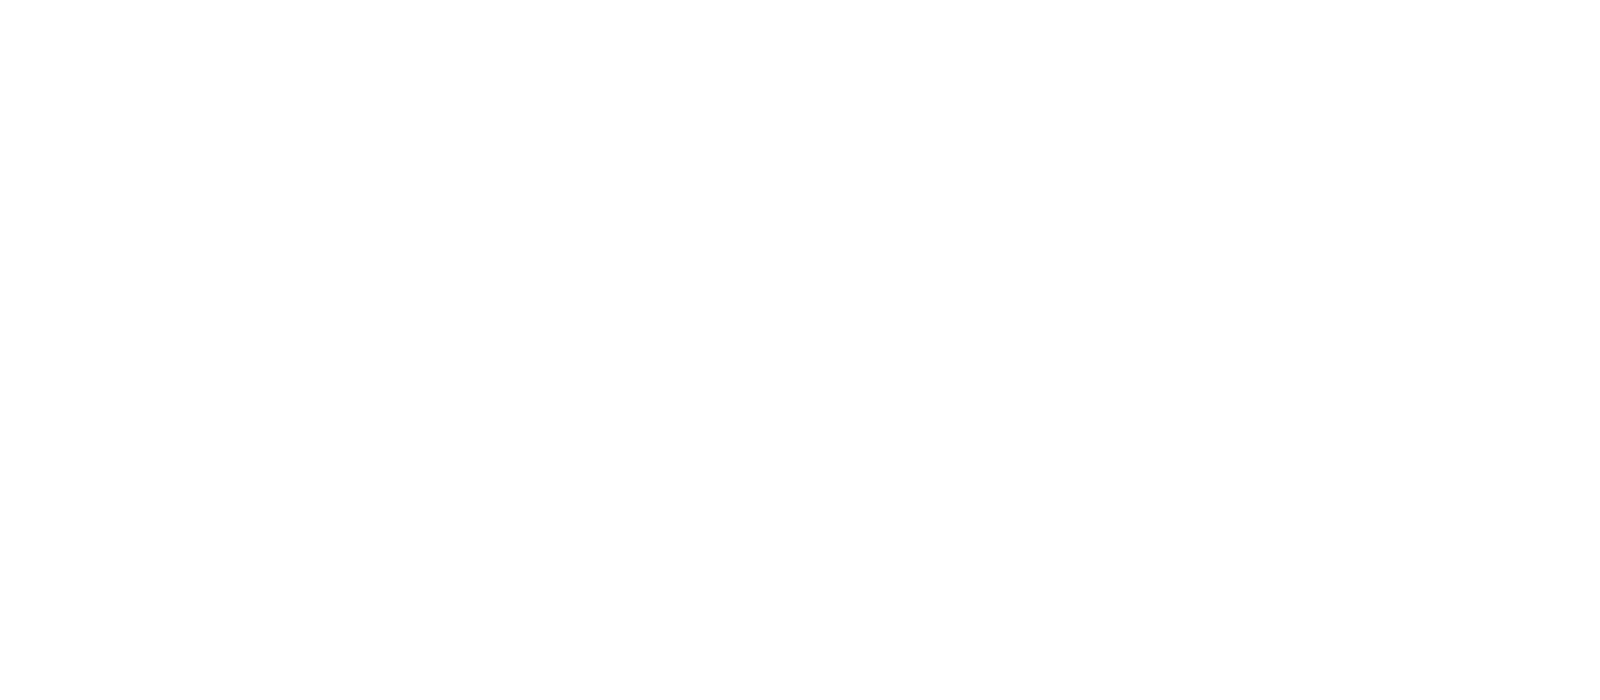

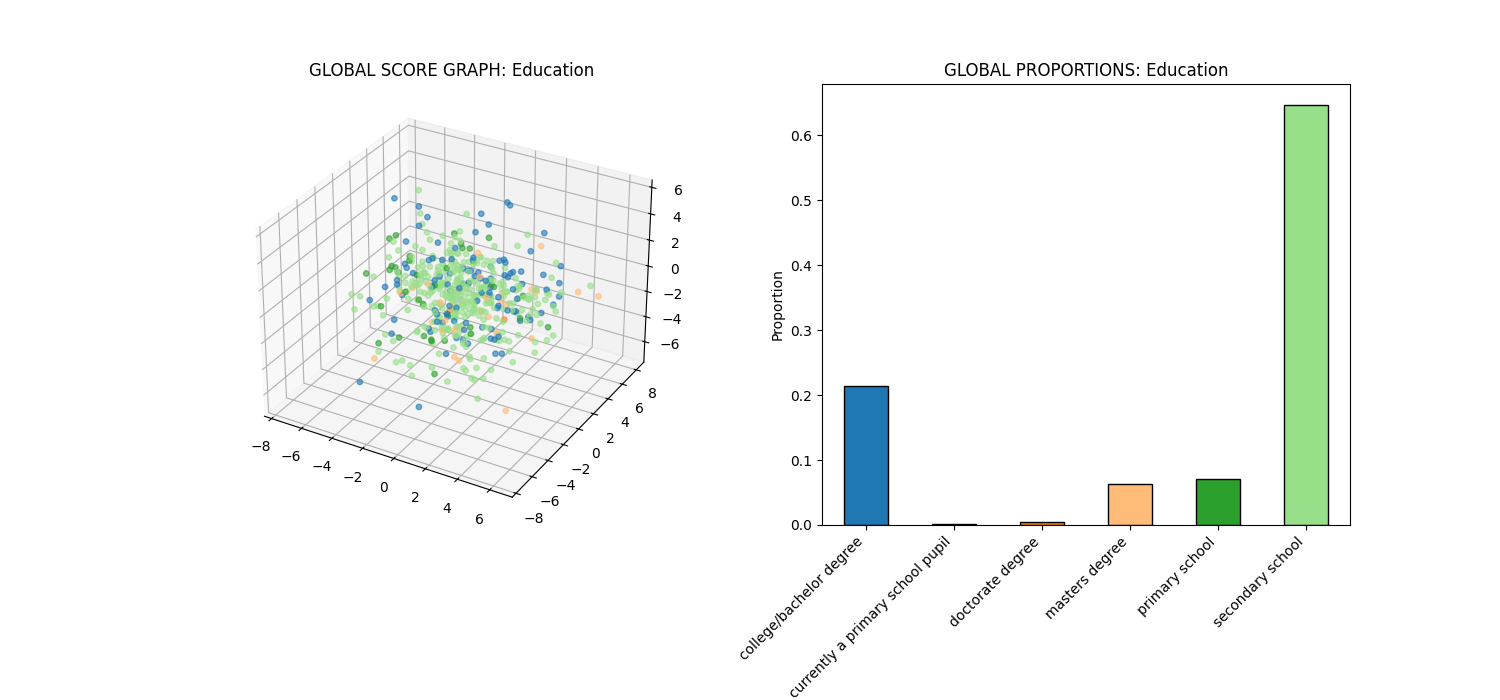

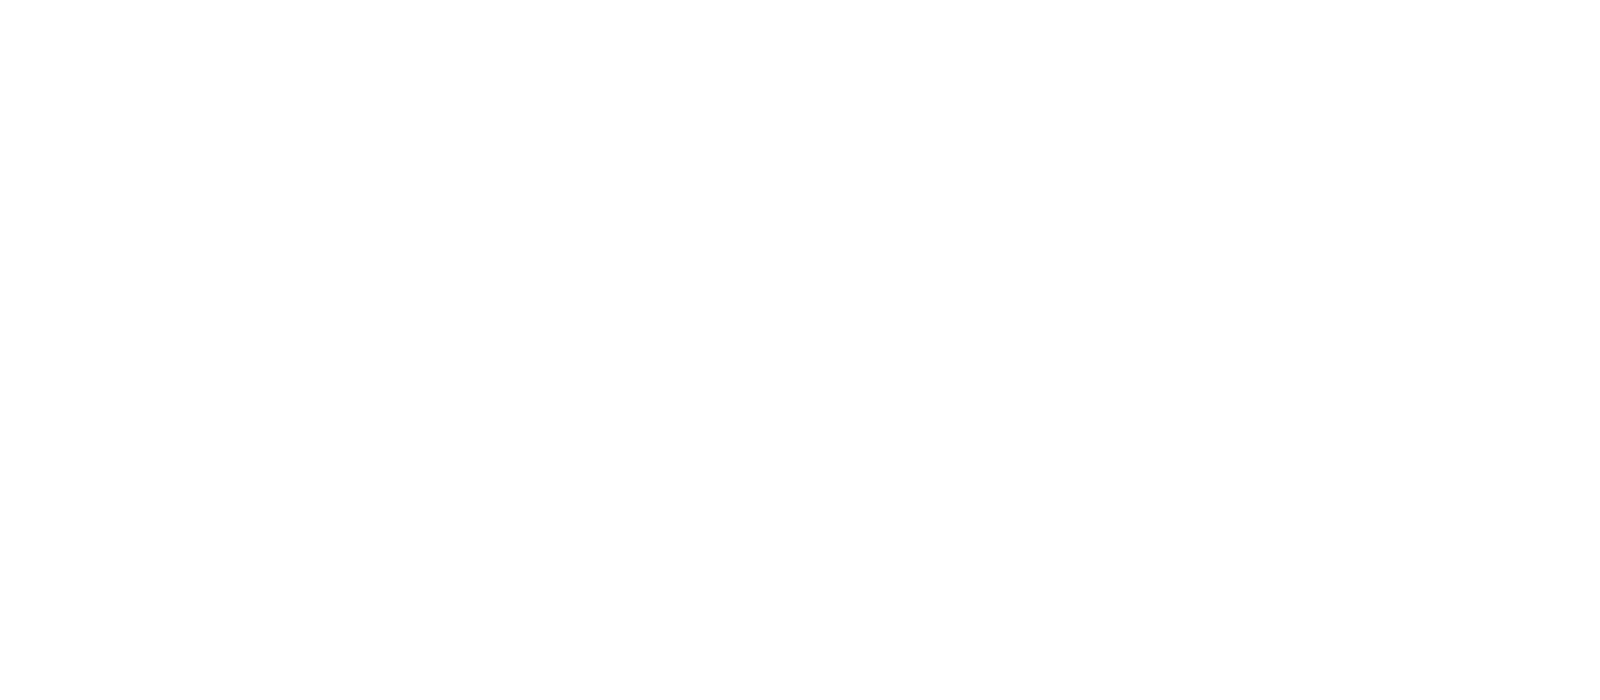

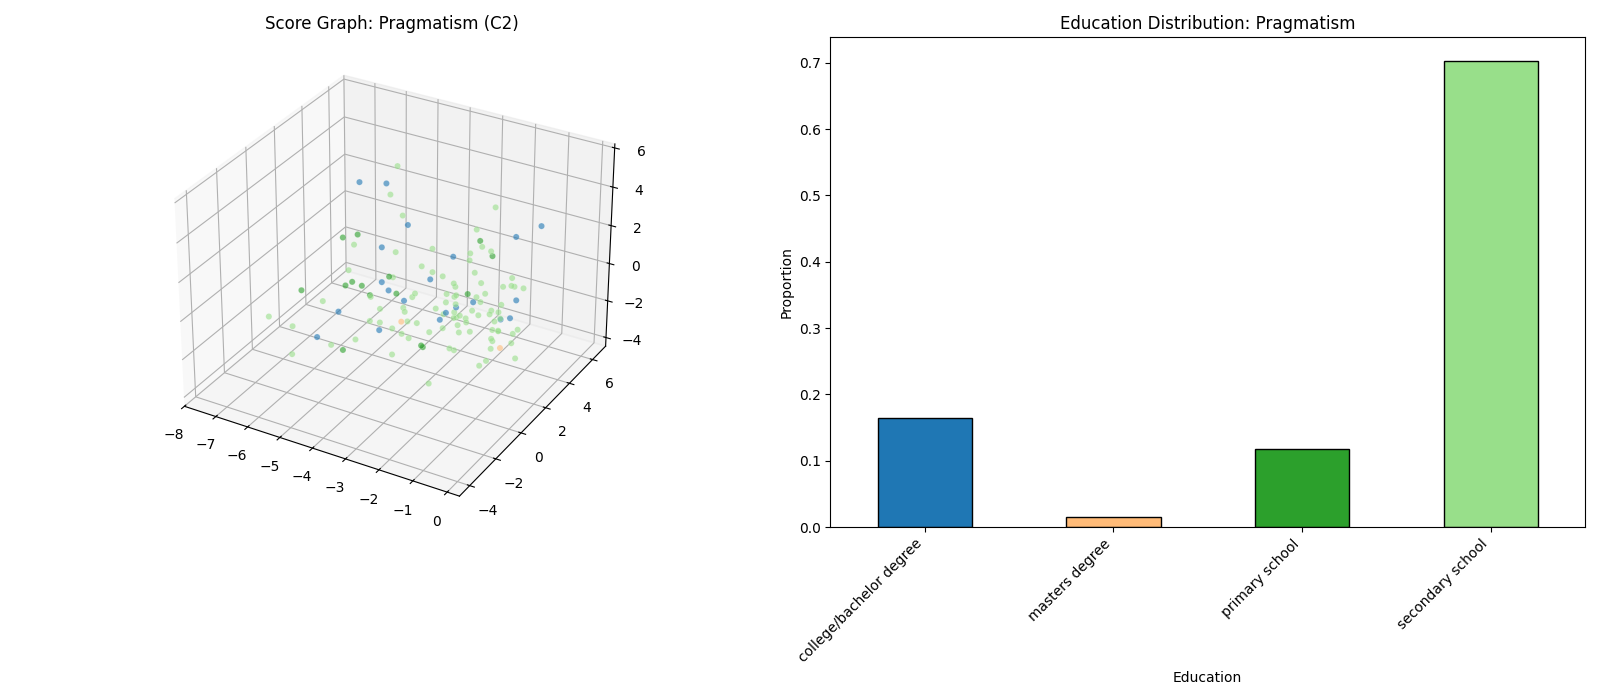

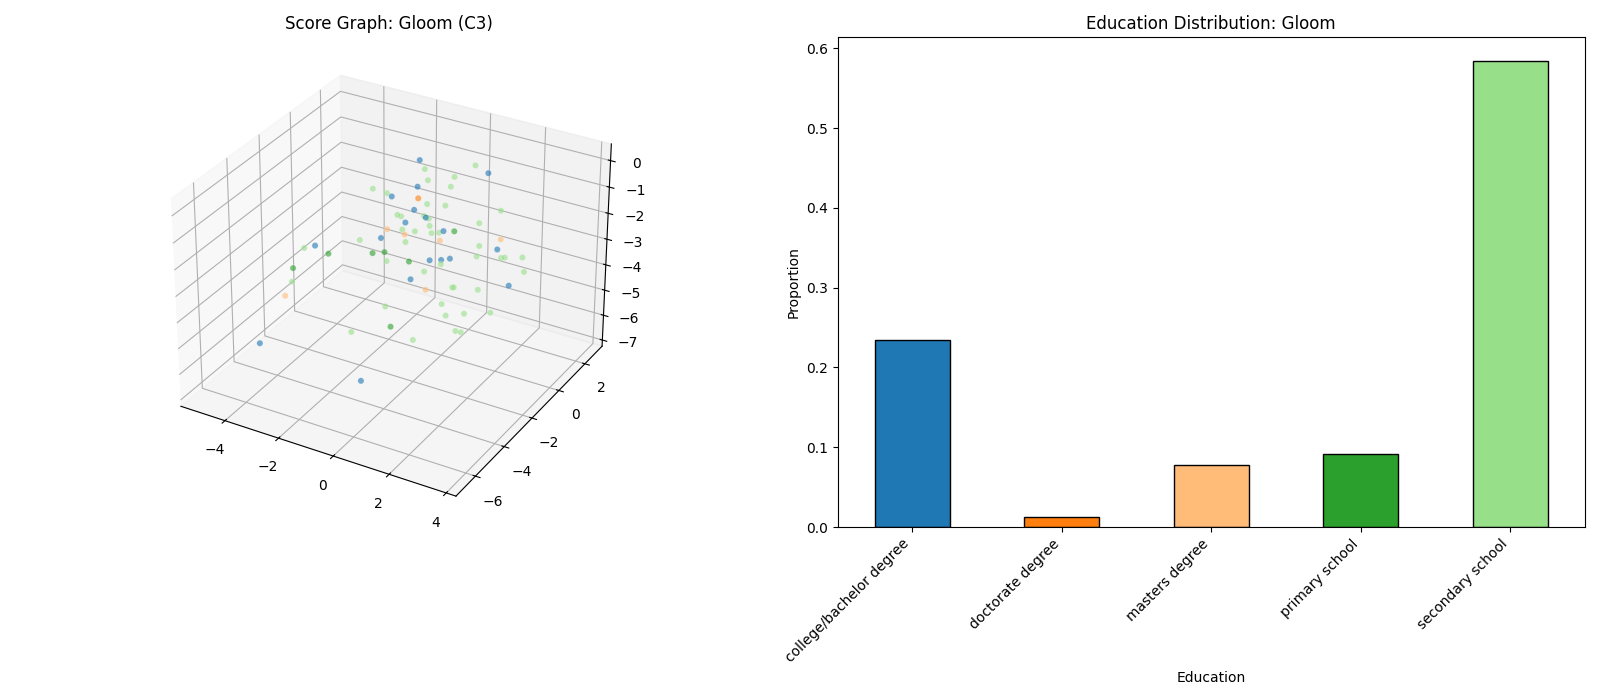

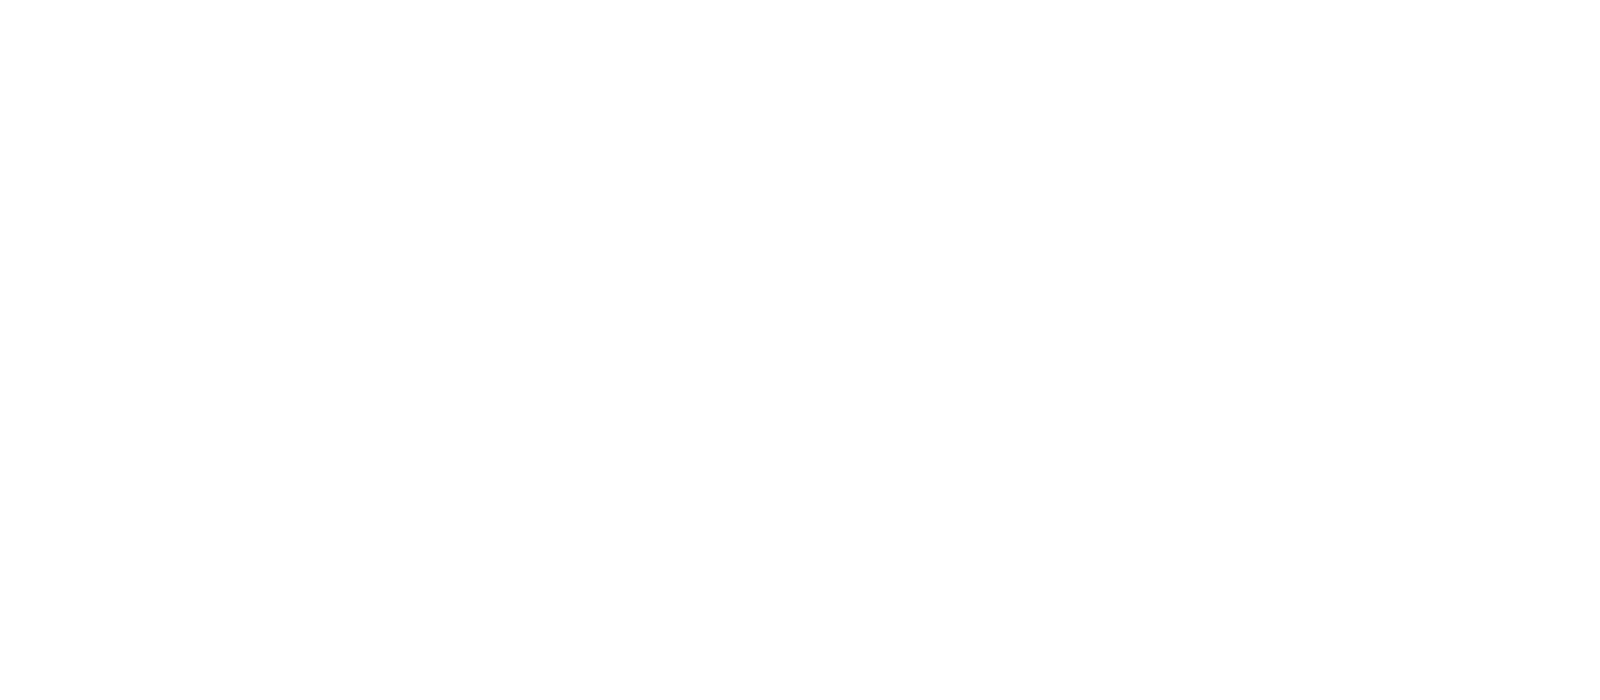

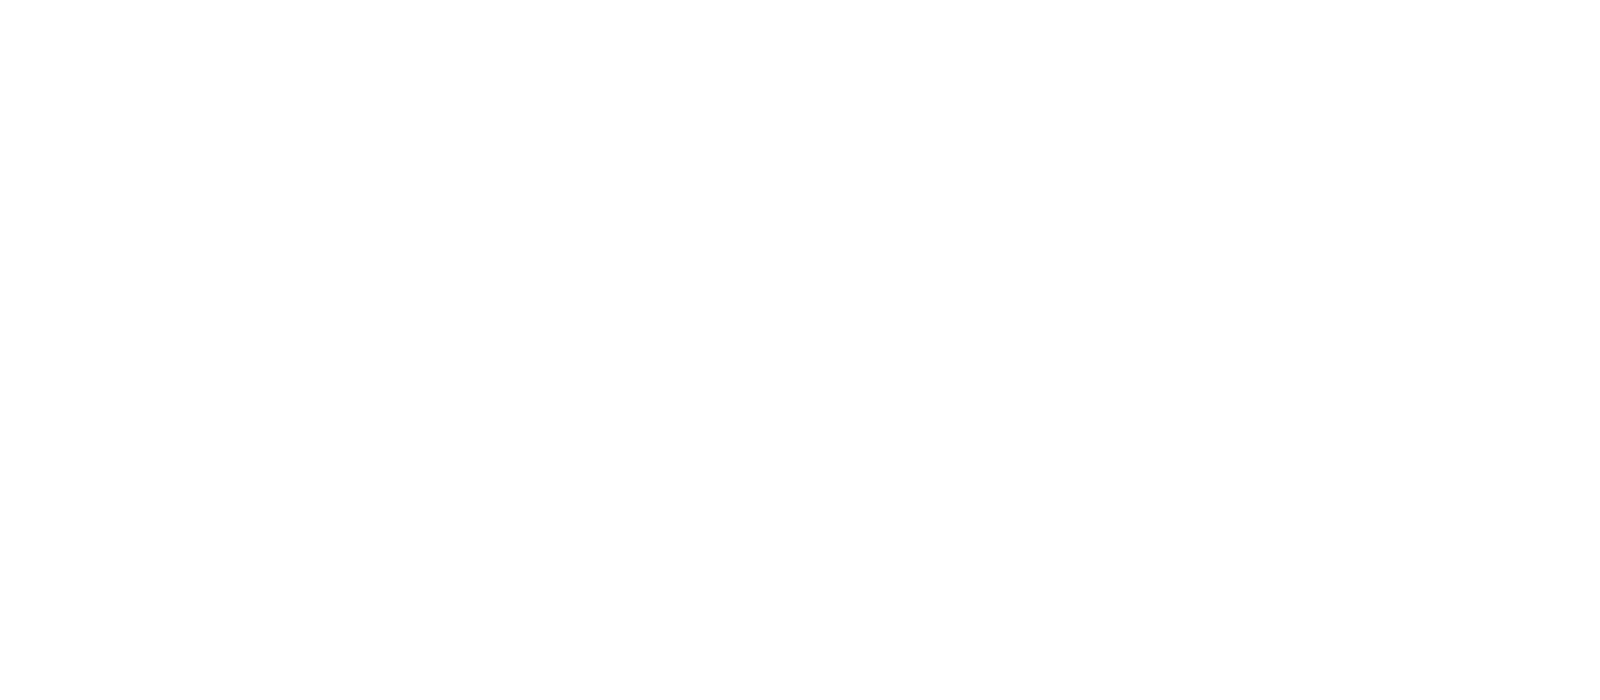

In [15]:
selected_labels = ['Age', 'Gender', 'Education']
centroid_names = ['Method','Pragmatism','Gloom','Simplicity','Romance']

gender_colors = {'male': '#1f77b4', 'female': '#d62728'} 

responses_lb = responses_lb.copy()
responses_lb['cluster'] = km.labels_

for label in selected_labels:
    lb_values = np.sort(responses_lb[label].unique())
    label_to_color = {}

    if label == 'Gender':
        for val in lb_values:
            label_to_color[val] = gender_colors.get(val, 'gray')
    
    elif label == 'Age':
        cmap = matplotlib.colormaps.get_cmap('viridis')
        norm = plt.Normalize(vmin=lb_values.min(), vmax=lb_values.max())
        for val in lb_values:
            label_to_color[val] = cmap(norm(val))
            
    else: 
        cmap = matplotlib.colormaps.get_cmap('tab20')
        for i, val in enumerate(lb_values):
            label_to_color[val] = cmap(i % 10)

    color_scat_global = [label_to_color[val] for val in responses_lb[label].values]

    fig_global = plt.figure(figsize=(15, 7)) 
    
    ax1 = fig_global.add_subplot(1, 2, 1, projection='3d')
    ax1.scatter(scores[:, 0], scores[:, 1], scores[:, 2], s=15, c=color_scat_global, alpha=0.6)
    ax1.set_title(f'GLOBAL SCORE GRAPH: {label}')
    
    ax2 = fig_global.add_subplot(1, 2, 2)
    counts = responses_lb[label].value_counts(normalize=True).sort_index()
    bars = counts.plot(kind='bar', ax=ax2, edgecolor='black')
    for i, patch in enumerate(bars.patches):
        patch.set_facecolor(label_to_color[counts.index[i]])
    
    ax2.set_title(f'GLOBAL PROPORTIONS: {label}')
    ax2.set_ylabel('Proportion')
    
    
    plt.xticks(rotation=45, ha='right')
    plt.subplots_adjust(bottom=0.25) 
    plt.show()

    for k in range(k_best):
        fig_cluster = plt.figure(figsize=(16, 7))
        
        
        ax_3d = fig_cluster.add_subplot(1, 2, 1, projection='3d')
        idx = np.where(km.labels_ == k)[0]
        cluster_colors = [color_scat_global[i] for i in idx]
        
        ax_3d.scatter(scores[idx, 0], scores[idx, 1], scores[idx, 2], s=20, c=cluster_colors, alpha=0.6, edgecolor='w', linewidth=0.2)
        ax_3d.set_title(f'Score Graph: {centroid_names[k]} (C{k+1})')
        
        
        ax_bar = fig_cluster.add_subplot(1, 2, 2)
        cluster_data = responses_lb[responses_lb['cluster'] == k][label]
        c_counts = cluster_data.value_counts(normalize=True).sort_index()
        
        bars = c_counts.plot(kind='bar', ax=ax_bar, edgecolor='black')
        for i, patch in enumerate(bars.patches):
            patch.set_facecolor(label_to_color[c_counts.index[i]])
            
        ax_bar.set_title(f'{label} Distribution: {centroid_names[k]}')
        ax_bar.set_ylabel('Proportion')
        #ax_bar.set_ylim(0, counts.max() + 0.1) 
        
    
        plt.setp(ax_bar.get_xticklabels(), rotation=45, ha='right')
        
        plt.tight_layout()
        plt.show()

## Cluster Internal Evaluations

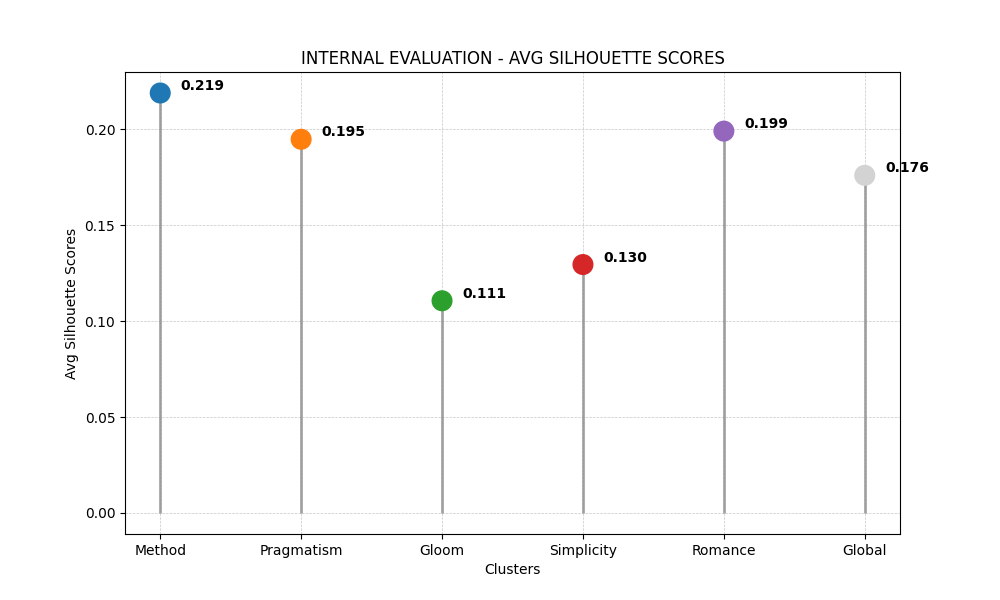

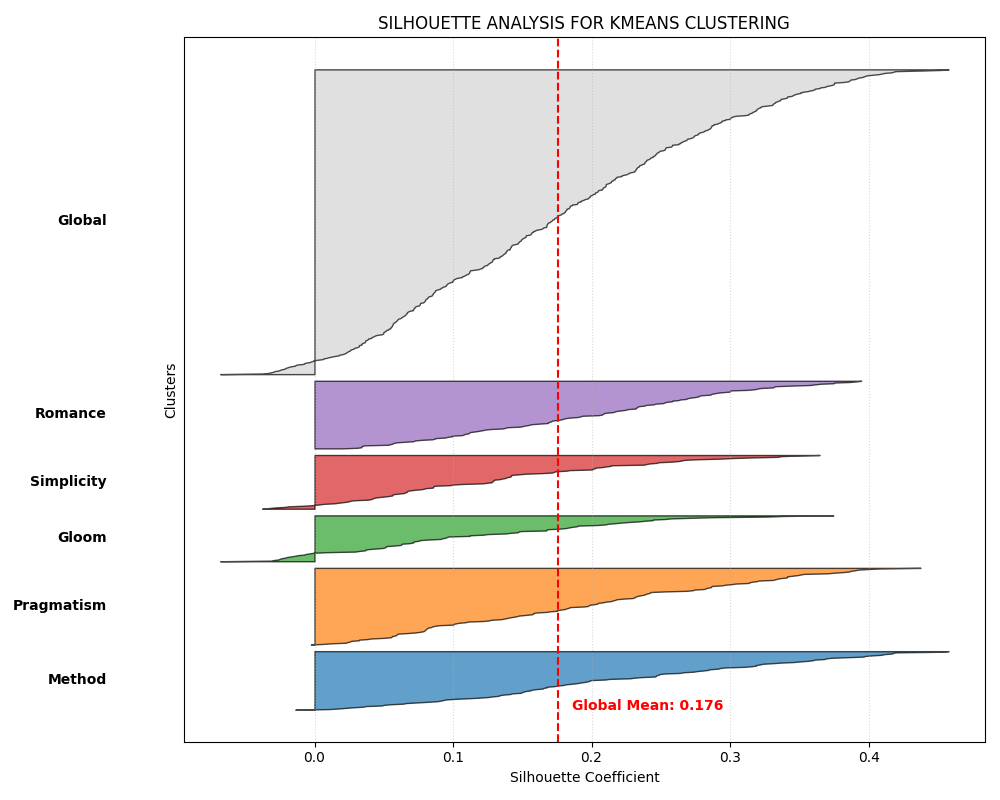

In [18]:
silscores = silhouette_samples(scores, km.labels_)
m = np.mean(silscores)
cluster_silscores = [np.mean(silscores[km.labels_ == kk]) for kk in range(k_best)]

silcoeffs_df = pd.DataFrame(
    np.array(cluster_silscores + [m]),
    index = centroid_names + ['Global'],
    columns = ['Sil. Score']
)

plt.figure(figsize=(10, 6))
colors = [plt.cm.tab10(i) for i in range(k_best)] + ['lightgrey'] 
plt.vlines(x=silcoeffs_df.index.tolist(), ymin=0, ymax=silcoeffs_df['Sil. Score'].values, 
           color='gray', alpha=0.7, linewidth=2)
plt.scatter(silcoeffs_df.index.tolist(), silcoeffs_df['Sil. Score'].values, 
            color=colors, s=200, zorder=3)

for i, score in enumerate(silcoeffs_df['Sil. Score'].values):
    plt.text(
        x=i+0.3,               
        y=score,   
        s=f'{score:.3f}',  
        ha='center',       
        va='bottom',       
        fontweight='bold',
        fontsize=10
    )

plt.xlabel('Clusters')
plt.ylabel('Avg Silhouette Scores')
plt.title('INTERNAL EVALUATION - AVG SILHOUETTE SCORES')
plt.grid(True, linestyle='--', linewidth=0.5, alpha=0.7)

plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
y_lower = 10 
for i in range(k_best):
    ith_cluster_sil_values = silscores[km.labels_ == i]
    ith_cluster_sil_values.sort()
    size_cluster_i = ith_cluster_sil_values.shape[0]
    y_upper = y_lower + size_cluster_i
    cluster_color = plt.cm.tab10(i) 
    ax.fill_betweenx(np.arange(y_lower, y_upper),
                      0, ith_cluster_sil_values,
                      facecolor=cluster_color, edgecolor='black', alpha=0.7)
    ax.text(-0.15, y_lower + 0.5 * size_cluster_i, centroid_names[i], 
            ha='right', va='center', fontsize=10, fontweight='bold')
    y_lower = y_upper + 10 

all_sil_values = silscores.copy()
all_sil_values.sort()

size_global = all_sil_values.shape[0]
y_upper = y_lower + size_global

ax.fill_betweenx(np.arange(y_lower, y_upper),
                  0, all_sil_values,
                  facecolor='lightgrey', edgecolor='black', alpha=0.7)

ax.text(-0.15, y_lower + 0.5 * size_global, 'Global', 
        ha='right', va='center', fontsize=10, fontweight='bold')

ax.set_title("SILHOUETTE ANALYSIS FOR KMEANS CLUSTERING")
ax.set_xlabel("Silhouette Coefficient")
ax.set_ylabel("Clusters")


ax.axvline(x=m, color="red", linestyle="--")
ax.text(m + 0.01, 10, f'Global Mean: {m:.3f}', color='red', fontweight='bold')
ax.grid(axis='x', linestyle=':', alpha=0.5)
ax.set_yticks([])

plt.tight_layout()
plt.show()